# 01 – Thu thập dữ liệu và EDA

Notebook của M1. Phần đầu (mục 1–4) làm task **M1-01** (xác minh nguồn, schema) và **M1-02** (trích xuất dữ liệu thô). Phần sau (mục 5–8) làm **M1-03** (EDA định lượng) và **M1-04** (EDA trực quan) trên chính file thô đó.

**Tải dữ liệu phải chạy trên Google Colab**: cổng dữ liệu Chicago trả lỗi 403 khi truy cập từ máy ở Việt Nam (đã thử lại ngày 18/11/2026).

Mở trên Colab (nhánh của M1, đổi thành `main` sau khi merge):
https://colab.research.google.com/github/tanbentam/KhaiPhaDuLieu/blob/m1/extract-eda/notebooks/01_data_acquisition_eda.ipynb

Trước khi chạy trên Colab:
1. Trên Google Drive có thư mục `KhaiPhaDuLieu/data` (nằm trong My Drive, hoặc là shortcut đặt trong My Drive).
2. Nhánh ghi ở biến `BRANCH` đã được đẩy lên GitHub.

Nếu file thô đã có sẵn trong `data/raw/` thì notebook không tải lại, chỉ đọc và kiểm tra.

In [1]:
# ===== O THIET LAP (dua tren o dung chung cua notebook 00; them BRANCH va noi Drive) =====
# Colab: clone repo, cai thu vien, noi data/ voi Google Drive.
# May ca nhan: tu tim goc repo, khong cai gi them.
import os, sys, subprocess, pathlib

REPO_URL = "https://github.com/tanbentam/KhaiPhaDuLieu.git"
BRANCH = "main"
DRIVE_DIR = "KhaiPhaDuLieu"      # = MyDrive/KhaiPhaDuLieu/data
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    ROOT = pathlib.Path("/content/KhaiPhaDuLieu")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL, str(ROOT)], check=True)
    else:
        subprocess.run(["git", "-C", str(ROOT), "pull", "--ff-only"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")], check=True)
    os.chdir(ROOT)
else:
    here = pathlib.Path.cwd().resolve()
    ROOT = next(p for p in (here, *here.parents) if (p / "config" / "experiment.yaml").is_file())

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

if IN_COLAB:
    from src.colab import link_drive_data
    print("data/ ->", link_drive_data(DRIVE_DIR))   # file ghi vao data/ se nam luon tren Drive

print("Colab:", IN_COLAB, "| Goc repo:", ROOT.name)

Colab: False | Goc repo: KhaiPhaDuLieu


## 1. Tham số

Cửa sổ thời gian lấy từ mục `extract` của `config/experiment.yaml`. Giá trị hiện tại (17/04–14/05/2023) là **đề xuất**: bốn tuần trọn từ thứ Hai đến Chủ nhật, không có ngày lễ liên bang, không đổi giờ mùa hè, tuần đầu trùng tuần pilot của M2. Nhóm chốt trước khi tải.

In [2]:
import json
import pandas as pd
from src.config import load_config, resolve_path
from src.data import extract as E

cfg = load_config()
START, END = cfg["extract"]["start"], cfg["extract"]["end"]
RAW_DIR, MAN_DIR = resolve_path(cfg, "raw_dir"), resolve_path(cfg, "manifests_dir")
NAME = E.raw_name(START, END)
RAW_FILE = RAW_DIR / f"{NAME}.parquet"
MAN_FILE = MAN_DIR / f"{NAME}_manifest.json"
print("Cua so  :", START, "..", END)
print("File tho:", RAW_FILE.relative_to(ROOT), "| da co:", RAW_FILE.exists())

Cua so  : 2023-04-17 .. 2023-05-14
File tho: data/raw/raw_extract_20230417_20230514.parquet | da co: True


## 2. Xác minh nguồn và schema (M1-01)

Đọc metadata thật của cổng dữ liệu và đối chiếu 17 cột cần lấy. Thiếu cột nào thì dừng và báo tên cột. Ô này cần gọi được cổng dữ liệu, nên chỉ chạy trên Colab.

In [3]:
if RAW_FILE.exists():
    print("File tho da co -> doc schema da luu luc tai.")
    snap = json.loads((MAN_DIR / "schema_snapshot.json").read_text(encoding="utf-8"))
elif IN_COLAB:
    meta = E.fetch_metadata()
    E.check_columns(meta)
    snap = E.schema_snapshot(meta)
    print("Bo du lieu:", snap["name"], "|", snap["n_columns"], "cot | nguon cap nhat:", snap["rows_updated_at_utc"])
else:
    snap = None
    print("May ca nhan va chua co file tho. Chay notebook nay tren Colab, roi tai", RAW_FILE.name,
          "va thu muc manifests tu Drive ve data/.")

if snap:
    dd = E.data_dictionary(snap)
    display(dd[dd.used_by_m1][["field_name", "internal_name", "source_type", "unit", "role"]])

File tho da co -> doc schema da luu luc tai.


,field_name,internal_name,source_type,unit,role
0,trip_id,trip_id,text,,Khoa chuyen di; dung de tai lap mau
2,trip_start_timestamp,trip_start_timestamp,calendar_date,"gio dia phuong Chicago, lam tron 15 phut","Thoi diem don; tao pickup_hour, weekday, time_..."
3,trip_end_timestamp,trip_end_timestamp,calendar_date,"gio dia phuong Chicago, lam tron 15 phut",Kiem tra end < start
4,trip_seconds,trip_seconds,number,giay,EDA va co chat luong; KHONG dua vao mo hinh
5,trip_miles,trip_miles,number,dam (mile),EDA va co chat luong; KHONG dua vao mo hinh
6,pickup_census_tract,pickup_census_tract,text,ma census tract,EDA khong gian; co the bi an
7,dropoff_census_tract,dropoff_census_tract,text,ma census tract,EDA khong gian; co the bi an
8,pickup_community_area,pickup_community_area,number,ma khu 1-77,Dien giai cum nam o khu nao
9,dropoff_community_area,dropoff_community_area,number,ma khu 1-77,Nhanh doi chieu drop-off
10,fare,fare,number,USD,EDA; KHONG dua vao mo hinh


## 3. Đếm và tải dữ liệu thô (M1-02)

`build_raw_extract` đếm số dòng trên server, tải theo trang 50.000 dòng (sắp theo `trip_id`), rồi đối chiếu số dòng. Mỗi trang được lưu thành một file tạm, nên nếu Colab bị ngắt thì chạy lại ô này sẽ tải tiếp từ chỗ dừng. Số dòng lệch với server thì hàm báo lỗi và không ghi file.

File thô là bất biến: giữ nguyên giá trị như API trả về, không lọc dòng nào, và không bị ghi đè nếu đã tồn tại.

In [4]:
if RAW_FILE.exists():
    man = json.loads(MAN_FILE.read_text(encoding="utf-8"))
    print("Da co file tho, khong tai lai.")
elif IN_COLAB:
    man = E.build_raw_extract(START, END, RAW_DIR, MAN_DIR)
else:
    man = None

if man:
    print("Server dem :", f"{man['rows_server_count']:,}")
    print("Tai ve     :", f"{man['rows_raw']:,}")
    print("Dung luong :", f"{man['file_size_bytes'] / 1e6:.1f} MB")
    print("sha256     :", man["sha256"])

Da co file tho, khong tai lai.
Server dem : 554,794
Tai ve     : 554,794
Dung luong : 31.6 MB
sha256     : f249fc450c7d0d3cd9f7ce3a5ccb5d5b8bf251d9bc43e1a2eafe3ca1ceafcaa1


## 4. Kiểm tra nhanh file thô

Kiểm tra file đọc được, khớp manifest và đúng cửa sổ thời gian. Đây chưa phải EDA; các con số dưới đây chỉ để xác nhận việc tải.

In [5]:
if man:
    raw = pd.read_parquet(RAW_FILE)
    df = E.parse_types(raw)
    assert len(raw) == man["rows_raw"], "so dong khac manifest"
    assert list(raw.columns) == E.COLUMNS, "cot khac danh sach da chon"
    assert E.sha256(RAW_FILE) == man["sha256"], "sha256 khac manifest"
    ts = df["trip_start_timestamp"]
    print("So dong            :", f"{len(df):,}", "|", df.shape[1], "cot")
    print("Thoi gian          :", ts.min(), "..", ts.max(), "|", ts.dt.date.nunique(), "ngay")
    print("Phut trong du lieu :", sorted(int(m) for m in ts.dt.minute.dropna().unique()))
    print("trip_id trung      :", int(raw["trip_id"].duplicated().sum()))
    xy = df[["pickup_centroid_latitude", "pickup_centroid_longitude"]]
    print("Thieu toa do pickup:", f"{xy.isna().any(axis=1).mean():.2%}")
    print("Toa do pickup khac nhau:", f"{len(xy.dropna().drop_duplicates()):,}")
    display(raw.isna().mean().mul(100).round(2).rename("ty le thieu (%)").to_frame())
    display(df.groupby(ts.dt.date).size().rename("so chuyen").to_frame().T)

So dong            : 554,794 | 17 cot
Thoi gian          : 2023-04-17 00:00:00 .. 2023-05-14 23:45:00 | 28 ngay
Phut trong du lieu : [0, 15, 30, 45]
trip_id trung      : 0
Thieu toa do pickup: 3.54%
Toa do pickup khac nhau: 304


,ty le thieu (%)
trip_id,0.00
trip_start_timestamp,0.00
trip_end_timestamp,0.00
trip_seconds,0.02
trip_miles,0.00
pickup_census_tract,51.80
dropoff_census_tract,53.17
pickup_community_area,3.58
dropoff_community_area,9.79
fare,0.13


trip_start_timestamp,2023-04-17,2023-04-18,2023-04-19,2023-04-20,2023-04-21,2023-04-22,2023-04-23,2023-04-24,2023-04-25,2023-04-26,...,2023-05-05,2023-05-06,2023-05-07,2023-05-08,2023-05-09,2023-05-10,2023-05-11,2023-05-12,2023-05-13,2023-05-14
so chuyen,22955,22257,22646,23963,21234,16233,14969,19788,20424,21535,...,22460,17677,17073,22454,21275,20716,20691,19871,13302,12909


## 5. EDA định lượng (M1-03)

Từ đây trở xuống chỉ **đếm và thống kê** trên file thô, không loại dòng nào. Việc loại dòng nằm ở notebook 02 và phải có cleaning log.

Các hàm nằm trong `src/data/eda.py`. Ba điều cần nhớ khi đọc số:
- Toạ độ là **tâm census tract / community area**, không phải GPS.
- Thời gian được **làm tròn 15 phút**.
- Số lượt đón là **nhu cầu taxi**, không phải mức độ ùn tắc.

In [6]:
from src.data import eda as A

METRICS_DIR = ROOT / "outputs" / "metrics"            # eda_summary.csv + thu muc eda/
FIG_DIR = resolve_path(cfg, "figures_dir") / "eda"    # 10 hinh PNG
NOTE = (f"Nguồn: Chicago Data Portal, Taxi Trips (wrvz-psew), {START} đến {END}. "
        "Toạ độ là tâm vùng; thời gian làm tròn 15 phút.")

if man:
    d = A.add_time_parts(df, cfg["time_slices"])      # them gio, thu, lat cat, toc do; khong mat dong
    assert len(d) == len(df)
    display(pd.DataFrame(A.overview(d, raw, man["file_size_bytes"], START, END),
                         columns=["nhom", "chi_so", "gia_tri"]))

,nhom,chi_so,gia_tri
0,quy_mo,rows,554794
1,quy_mo,columns,17
2,quy_mo,file_size_mb,31.59
3,quy_mo,unique_trip_id,554794
4,quy_mo,duplicate_rows,0
5,quy_mo,duplicate_pct,0.0
6,thoi_gian,timestamp_min,2023-04-17 00:00:00
7,thoi_gian,timestamp_max,2023-05-14 23:45:00
8,thoi_gian,days_expected,28
9,thoi_gian,days_present,28


### 5.1. Chất lượng: thiếu, trùng, giá trị không hợp lệ

Bảng thứ nhất là tỷ lệ thiếu của từng cột. Bảng thứ hai đếm từng loại vấn đề; cột `action` là cách xử lý **dự kiến** ở notebook 02 (`loai` = bỏ dòng, `danh dau` = giữ và gắn cờ, `giu` = giữ nguyên). Một dòng có thể dính nhiều quy tắc nên không cộng dồn các tỷ lệ.

In [7]:
if man:
    display(A.missing_table(raw))
    display(A.quality_table(d, START, END))

,column,n_missing,missing_pct
0,trip_id,0,0.0000
1,trip_start_timestamp,0,0.0000
2,trip_end_timestamp,6,0.0011
3,trip_seconds,86,0.0155
4,trip_miles,1,0.0002
5,pickup_census_tract,287373,51.7981
6,dropoff_census_tract,294967,53.1669
7,pickup_community_area,19888,3.5848
8,dropoff_community_area,54303,9.7880
9,fare,737,0.1328


,rule,n_rows,pct,action
0,trip_id thieu,0,0.0000,loai
1,trip_id trung (dong lap lai),0,0.0000,loai
2,thoi diem don thieu / khong doc duoc,0,0.0000,loai
3,thoi diem don ngoai cua so truy van,0,0.0000,loai
4,thieu toa do don,19627,3.5377,loai
5,toa do don ngoai khung Chicago,0,0.0000,loai
6,co toa do don nhung thieu ma khu (community area),261,0.0470,giu
7,thieu toa do tra,50550,9.1115,giu
8,thoi diem tra truoc thoi diem don,7,0.0013,danh dau
9,trip_seconds thieu,86,0.0155,danh dau


### 5.2. Phân phối thời lượng, quãng đường, cước

Phân phối chuyến đi lệch phải (ít chuyến rất dài kéo trung bình lên), nên đọc **trung vị, IQR, p90/p95** thay vì chỉ trung bình. `speed_mph` = quãng đường / thời lượng, chỉ tính khi thời lượng > 0.

In [8]:
if man:
    display(A.numeric_stats(d))

,variable,n,n_missing,zero_pct,negative_pct,min,mean,median,std,q1,q3,iqr,p90,p95,p99,max
0,trip_seconds,554708,86,1.989,0.0,0.0,1302.141,979.500,1697.329,480.000,1854.000,1374.000,2700.000,3215.000,4438.000,86206.00
1,trip_miles,554793,1,10.372,0.0,0.0,6.848,3.110,7.666,1.000,12.570,11.570,17.710,18.650,26.520,945.40
2,fare,554057,737,0.070,0.0,0.0,22.980,15.750,22.000,8.500,37.000,28.500,45.750,51.000,71.750,6602.25
3,tips,554057,737,44.129,0.0,0.0,3.244,2.000,4.341,0.000,5.000,5.000,9.900,11.440,15.900,120.00
4,trip_total,554057,737,0.067,0.0,0.0,28.854,19.200,41.110,10.250,47.000,36.750,60.000,67.000,97.500,9456.40
5,speed_mph,543674,11120,8.463,0.0,0.0,18.980,13.778,260.225,8.417,24.447,16.031,34.522,41.196,51.641,77076.00


### 5.3. Thời gian: theo ngày, thứ, giờ, lát cắt

Bảng theo ngày so mỗi ngày với trung vị của các ngày cùng thứ; `flag = True` là lệch quá 15%. Ngày bị đánh dấu cần được kiểm chứng (lễ, thời tiết, sự kiện) trước khi kết luận.

In [9]:
if man:
    by_date = A.daily_anomalies(A.counts_by_date(d))
    print("Ngay thieu trong cua so:", A.missing_dates(d, START, END) or "khong co")
    display(by_date[by_date["flag"]])
    display(A.counts_by_weekday(d))
    display(A.counts_by_slice(d))
    display(A.hour_weekday_matrix(d))

Ngay thieu trong cua so: khong co


,date,trips,weekday,weekday_name,median_same_weekday,deviation_pct,flag
26,2023-05-13,13302,5,Thứ 7,16177.5,-17.8,True
27,2023-05-14,12909,6,CN,15614.5,-17.3,True


,weekday,trips,n_days,trips_per_day,weekday_name
0,0,85749,4,21437.2,Thứ 2
1,1,83532,4,20883.0,Thứ 3
2,2,85783,4,21445.8,Thứ 4
3,3,89501,4,22375.2,Thứ 5
4,4,85684,4,21421.0,Thứ 6
5,5,63334,4,15833.5,Thứ 7
6,6,61211,4,15302.8,CN


,time_slice,trips,pct
0,OTHER,278011,50.11
1,WEEKDAY_AM,63046,11.36
2,WEEKDAY_PM,89192,16.08
3,WEEKEND,124545,22.45


pickup_hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
weekday,,,,,,,,,,,,,,,,,,,,,
0,365.8,249.2,135.0,82.2,120.2,254.2,468.2,778.8,1144.2,1266.2,...,1436.8,1482.5,1525.0,1546.0,1341.0,1202.8,961.2,699.0,514.5,375.8
1,266.5,161.5,89.0,59.5,80.5,197.5,421.5,822.5,1246.0,1381.5,...,1409.2,1436.0,1452.2,1464.8,1400.0,1209.8,1006.2,725.2,507.8,344.5
2,215.0,120.0,77.2,62.2,94.2,206.8,442.0,803.2,1198.8,1298.0,...,1437.0,1537.5,1531.0,1545.0,1397.2,1262.8,1069.0,871.5,662.0,446.5
3,273.8,176.8,90.0,76.2,109.5,249.8,422.2,766.0,1084.0,1266.2,...,1504.0,1545.5,1542.0,1542.5,1481.2,1393.8,1118.8,906.5,792.5,569.8
4,375.5,234.8,136.2,94.8,149.5,254.0,429.2,665.5,945.5,1095.0,...,1382.8,1385.8,1468.2,1519.8,1542.0,1382.5,1041.0,792.5,690.8,582.0
5,430.5,313.2,198.8,137.8,111.0,151.0,206.8,311.5,487.8,685.5,...,1016.5,1004.5,1065.5,1137.5,1108.0,1020.8,866.2,664.5,587.2,546.5
6,458.2,312.5,229.5,152.5,141.8,184.8,251.0,334.0,469.5,590.5,...,1007.5,1007.8,1022.8,1053.2,960.2,967.5,830.8,639.2,523.2,418.8


### 5.4. Không gian: toạ độ đón bị lặp nhiều đến mức nào

Đây là phần M2 và M3 cần nhất: số toạ độ khác nhau (tổng, theo lát cắt, theo tuần), tỷ trọng của các toạ độ đông nhất và số chuyến mỗi toạ độ. M2 dùng để đọc đồ thị k-distance của DBSCAN, M3 dùng để chọn `min_cluster_size` cho HDBSCAN.

In [10]:
if man:
    cc = A.coord_counts(d)
    display(pd.Series(A.coord_concentration(cc), name="gia_tri").to_frame())
    display(cc.head(10))
    display(A.coords_by_group(d, "time_slice"))
    display(A.coords_by_group(d.assign(week_start=A.week_start(d)), "week_start"))
    display(A.counts_by_area(d).head(10))

,gia_tri
unique_coords,304.00
trips_with_coords,535167.00
top1_share_pct,12.83
top2_share_pct,23.03
top5_share_pct,42.11
top10_share_pct,59.66
coords_for_50pct,7.00
coords_for_80pct,23.00
median_trips_per_coord,12.50
coords_lt_10_trips,145.00


,rank,lat,lon,trips,share_pct,cum_share_pct
0,1,41.979071,-87.903040,68646,12.827,12.827
1,2,41.980264,-87.913625,54611,10.204,23.032
2,3,41.899602,-87.633308,49597,9.268,32.299
3,4,41.884987,-87.620993,26982,5.042,37.341
4,5,41.880994,-87.632746,25525,4.770,42.110
5,6,41.878866,-87.625192,23994,4.483,46.594
6,7,41.874005,-87.663518,19066,3.563,50.156
7,8,41.879255,-87.642649,17551,3.280,53.436
8,9,41.944227,-87.655998,16997,3.176,56.612
9,10,41.859350,-87.617358,16288,3.044,59.656


,time_slice,trips_with_coords,unique_coords,top2_share_pct,top5_share_pct,median_trips_per_coord,coords_lt_10_trips
0,OTHER,267481,249,25.03,43.56,35.0,106
1,WEEKDAY_AM,60498,165,20.31,39.80,59.0,51
2,WEEKDAY_PM,86617,188,21.58,42.13,32.5,59
3,WEEKEND,120571,189,24.61,44.66,42.0,67


,week_start,trips_with_coords,unique_coords,top2_share_pct,top5_share_pct,median_trips_per_coord,coords_lt_10_trips
0,2023-04-17,138629,219,23.10,41.88,39.0,85
1,2023-04-24,134338,211,22.93,42.17,38.0,77
2,2023-05-01,135155,206,23.36,42.19,45.5,73
3,2023-05-08,127045,202,22.71,42.21,51.5,69


,pickup_community_area,trips,pct,cum_pct
0,76,123274,22.22,22.22
1,8,117622,21.2,43.42
2,32,90274,16.27,59.69
3,28,45118,8.13,67.82
4,33,30511,5.5,73.32
5,56,20783,3.75,77.07
6,<NA>,19888,3.58,80.65
7,6,18261,3.29,83.94
8,7,10830,1.95,85.89
9,3,7725,1.39,87.28


### 5.5. Ghi bảng ra file

- `outputs/metrics/eda_summary.csv`: mọi chỉ số chính ở dạng (group, metric, value). **Số trong báo cáo lấy từ file này.**
- `outputs/metrics/eda/*.csv`: 12 bảng chi tiết.
- `outputs/metrics/eda/data_quality_report.md`: báo cáo chất lượng, chỉ gồm số liệu.

In [11]:
if man:
    tables = A.write_tables(d, raw, METRICS_DIR, man["file_size_bytes"], START, END)
    report = A.write_quality_report(d, raw, METRICS_DIR / "eda" / "data_quality_report.md", START, END, NOTE)
    for name, path in {**tables, "data_quality_report": report}.items():
        print(f"{name:32s} {path.relative_to(ROOT)}")

eda_summary                      outputs/metrics/eda_summary.csv
missing_by_column                outputs/metrics/eda/missing_by_column.csv
numeric_stats                    outputs/metrics/eda/numeric_stats.csv
quality_checks                   outputs/metrics/eda/quality_checks.csv
trips_by_date                    outputs/metrics/eda/trips_by_date.csv
trips_by_hour                    outputs/metrics/eda/trips_by_hour.csv
trips_by_weekday                 outputs/metrics/eda/trips_by_weekday.csv
trips_hour_x_weekday             outputs/metrics/eda/trips_hour_x_weekday.csv
trips_by_time_slice              outputs/metrics/eda/trips_by_time_slice.csv
trips_by_pickup_area             outputs/metrics/eda/trips_by_pickup_area.csv
pickup_coords                    outputs/metrics/eda/pickup_coords.csv
pickup_coords_by_time_slice      outputs/metrics/eda/pickup_coords_by_time_slice.csv
pickup_coords_by_week            outputs/metrics/eda/pickup_coords_by_week.csv
data_quality_report              

## 6. EDA trực quan (M1-04)

Mười hình, lưu ở `outputs/figures/eda/`. Mỗi hình có tiêu đề, đơn vị, cỡ mẫu và nguồn ở chân hình.

| # | Hình | Để trả lời |
|---|---|---|
| 01, 02 | Histogram thời lượng, quãng đường (cắt trục tại p99) | Đuôi dài, giá trị 0 |
| 03 | Số chuyến theo giờ, ngày thường và cuối tuần | Giờ cao điểm, thấp điểm |
| 04 | Số chuyến theo thứ | Ngày thường so với cuối tuần |
| 05 | Heatmap giờ × thứ | Tổ hợp giờ/ngày đông nhất |
| 06 | Bản đồ điểm đón (1 chấm = 1 toạ độ) | Cấu trúc không gian sơ bộ |
| 07 | Điểm đón và điểm trả, cùng khung và cùng thang màu | Vùng đón có khác vùng trả không |
| 08 | Boxplot thang log | Biến lệch phải |
| 09 | Số chuyến mỗi ngày | Ngày bất thường |
| 10 | Tỷ trọng cộng dồn theo toạ độ | Mức dồn chuyến vào ít toạ độ |

Trong notebook, các hình được thu nhỏ và xếp thành lưới hai cột theo chủ đề để so sánh cạnh nhau; bấm vào hình để mở bản đầy đủ. File PNG trong `outputs/figures/eda/` vẫn giữ kích thước gốc để đưa vào báo cáo.

Hình 06 và 07 vẽ theo toạ độ khác nhau chứ không theo từng chuyến: hàng trăm nghìn chuyến nằm chồng lên vài trăm điểm, nên vẽ từng chuyến sẽ không thấy mật độ.


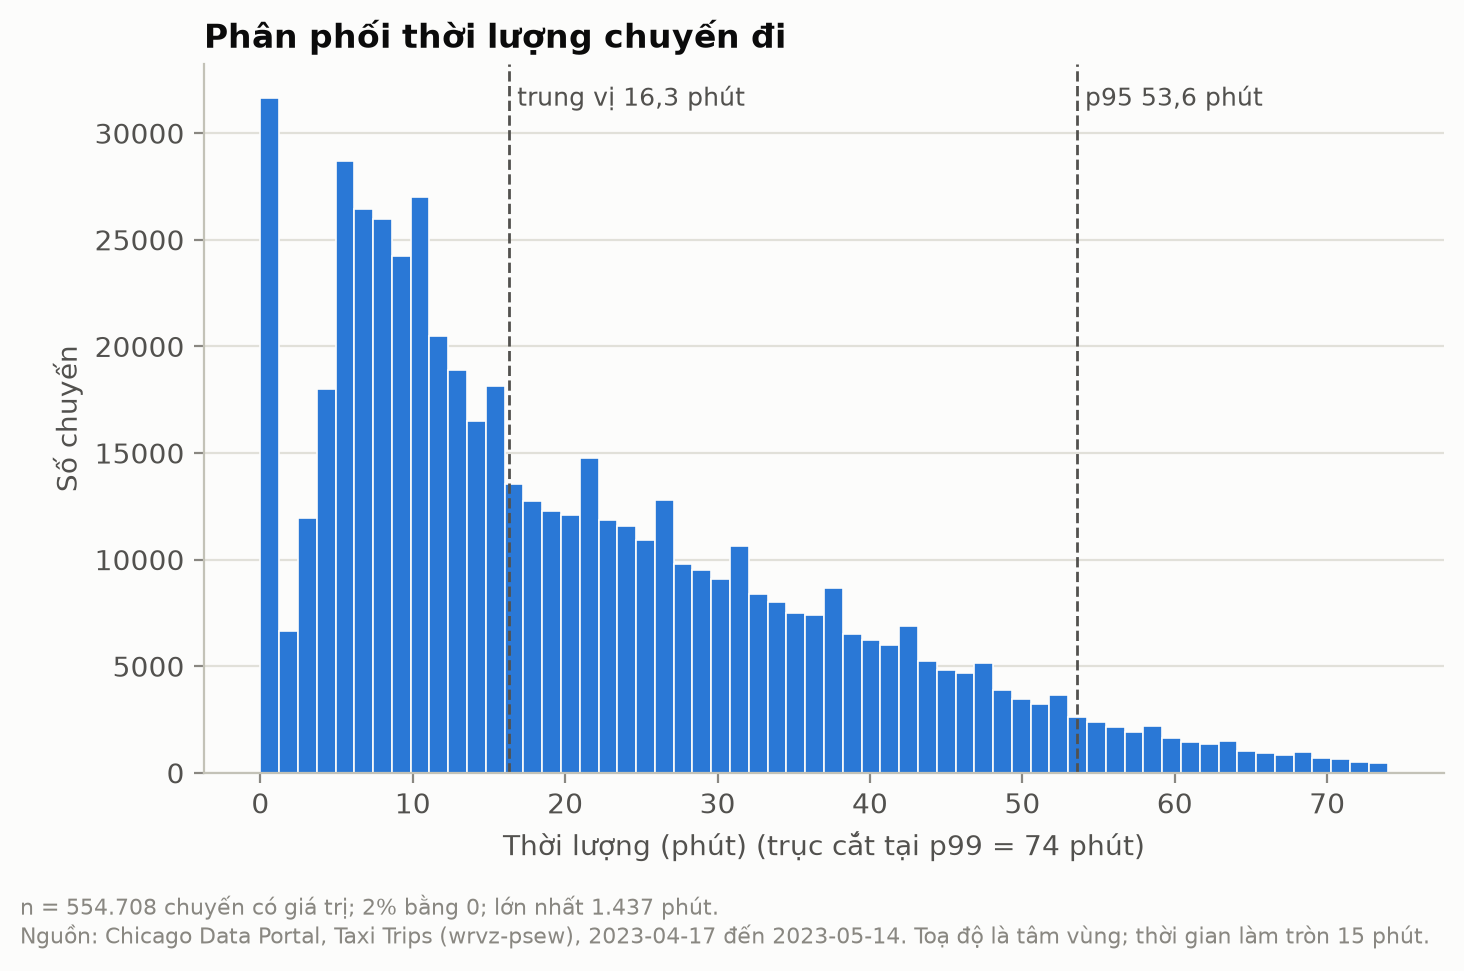
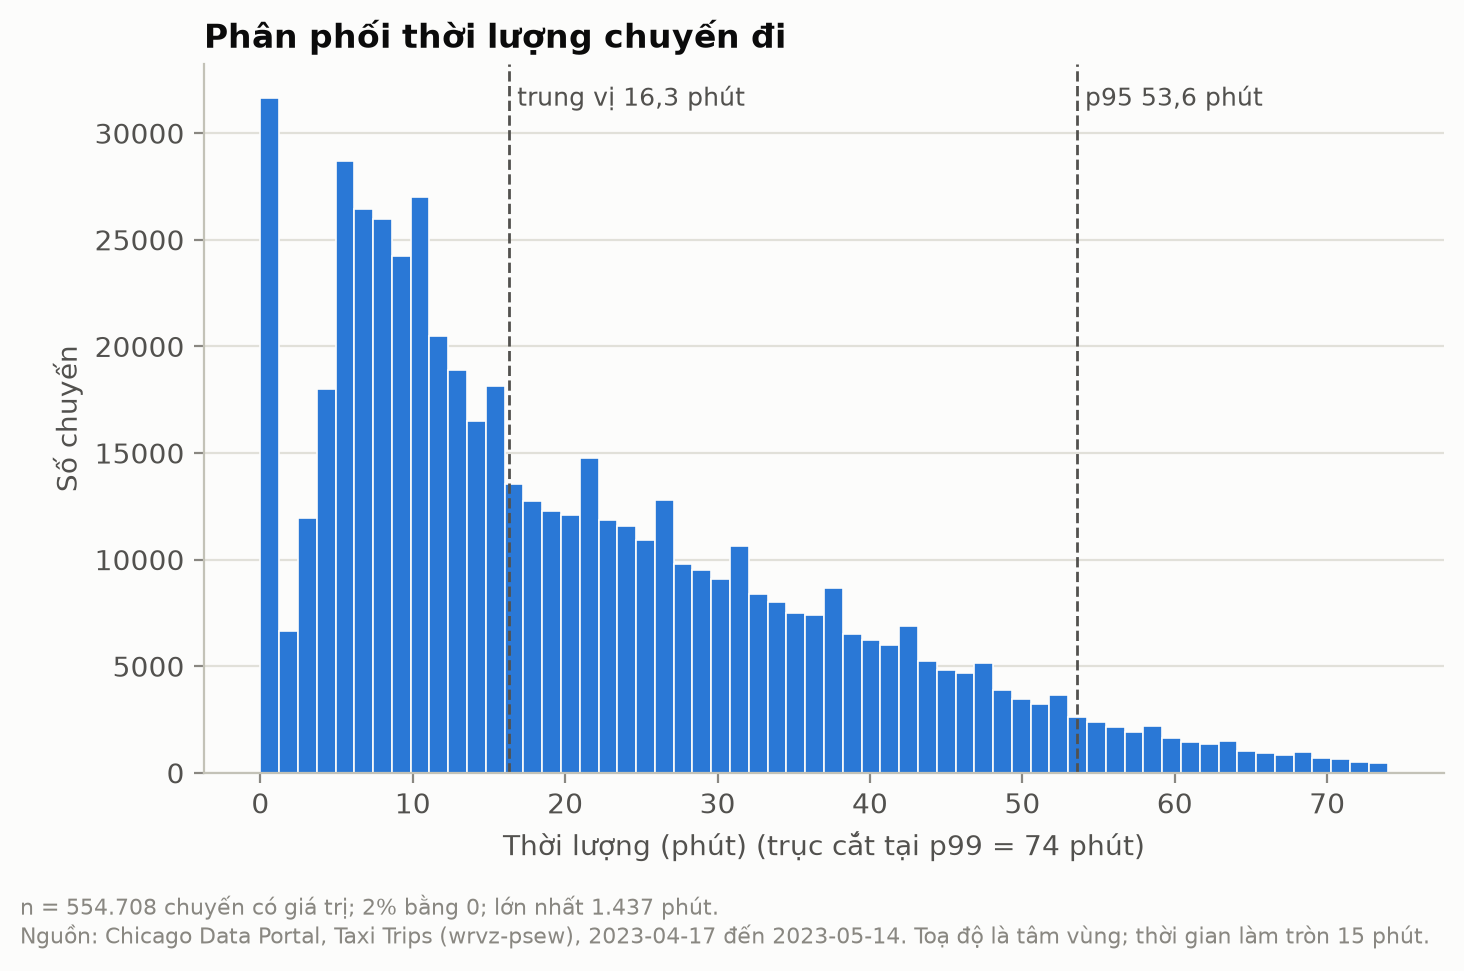
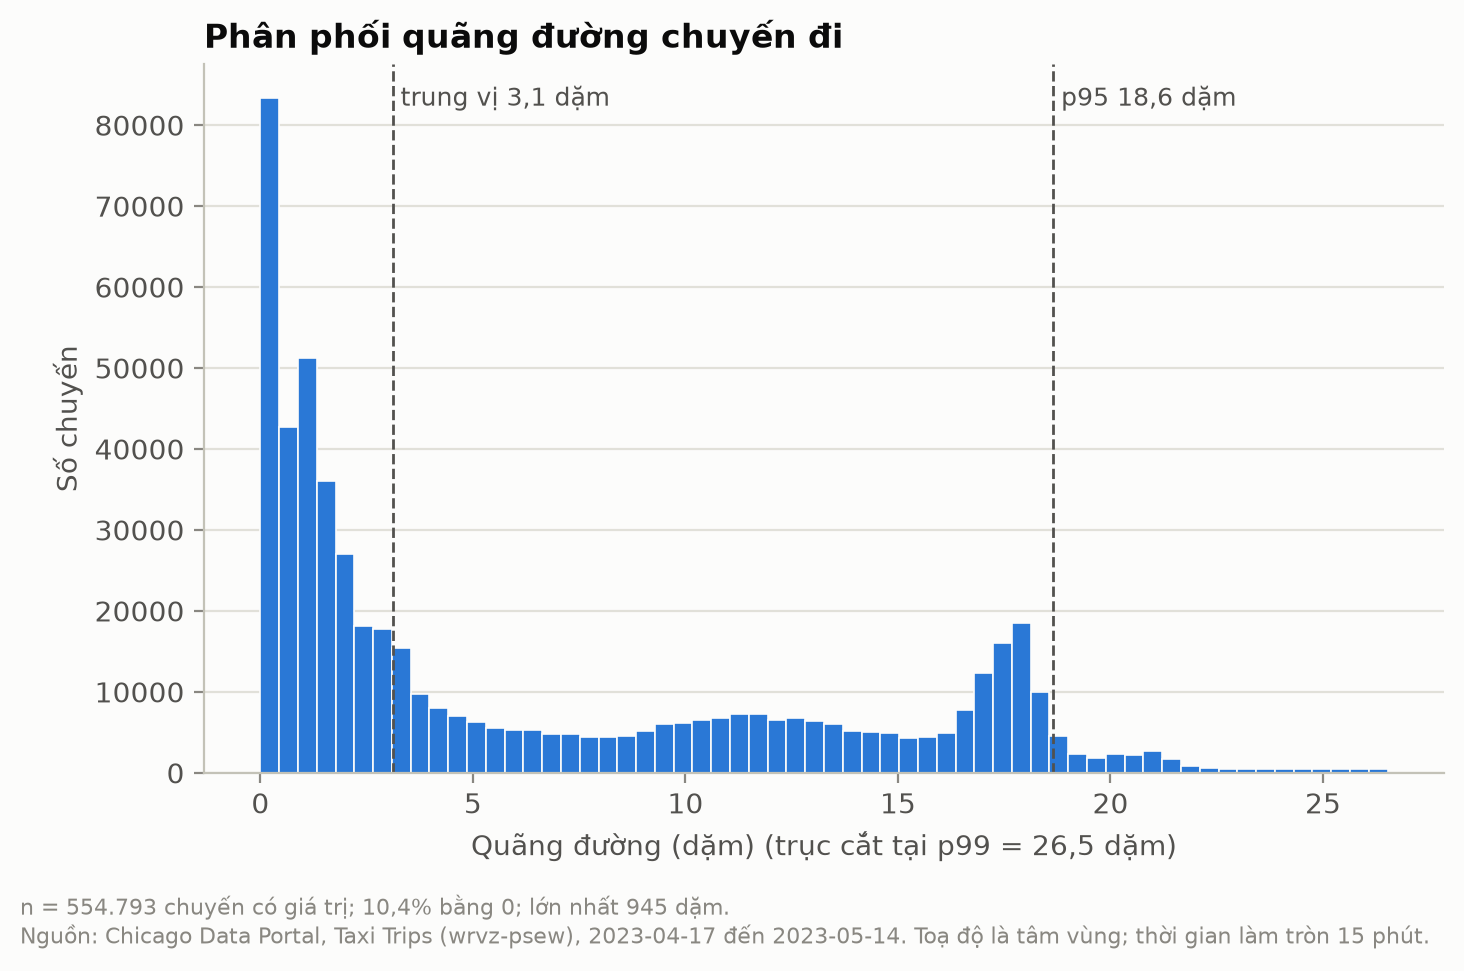
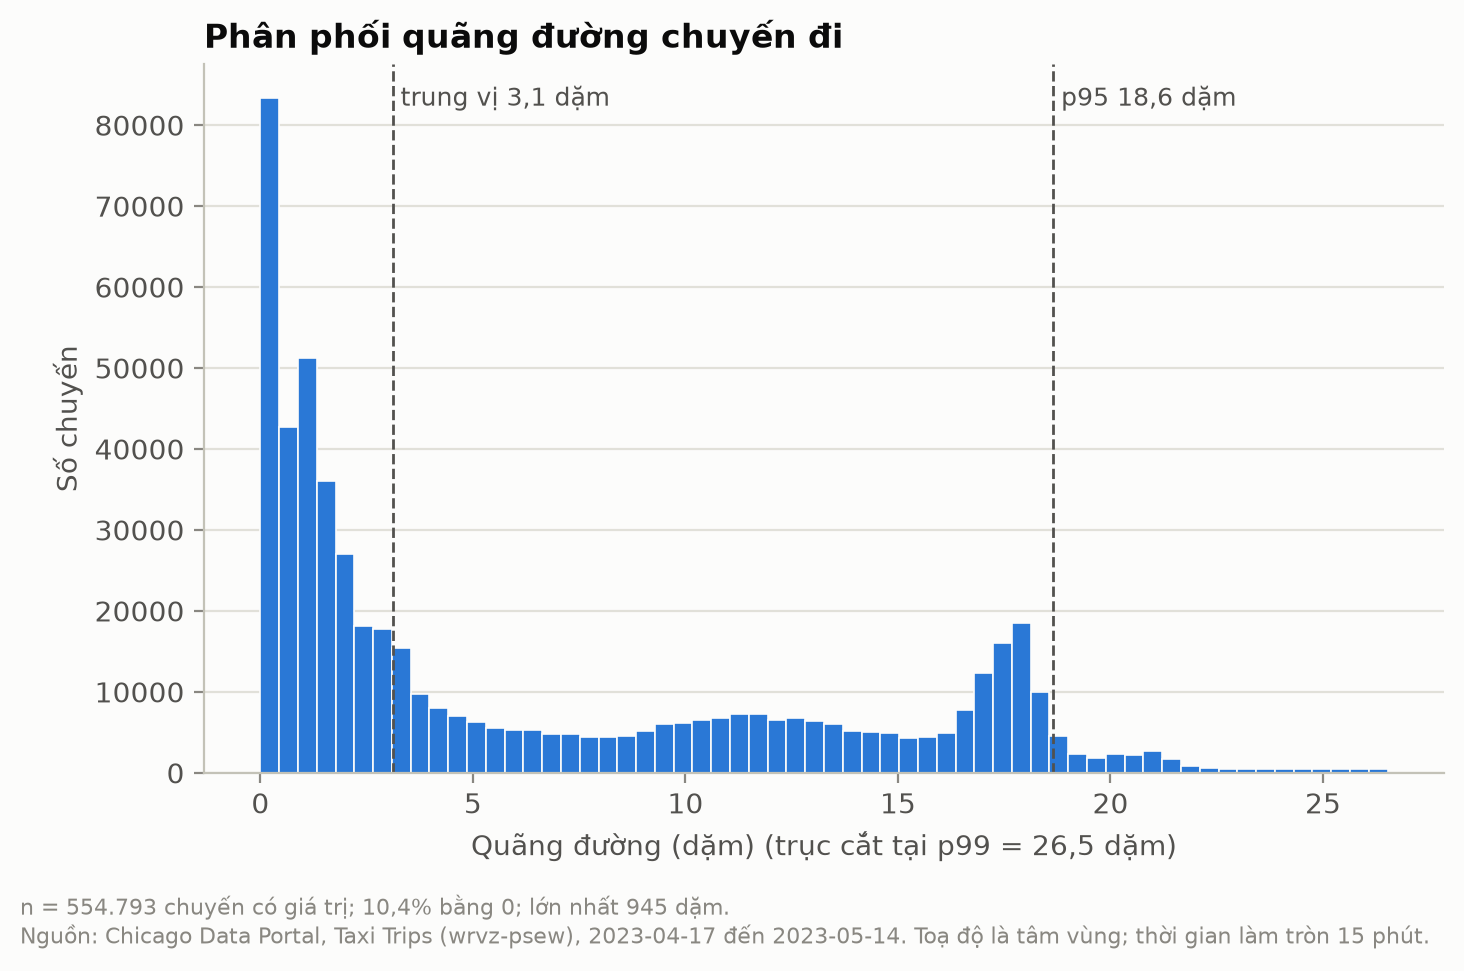
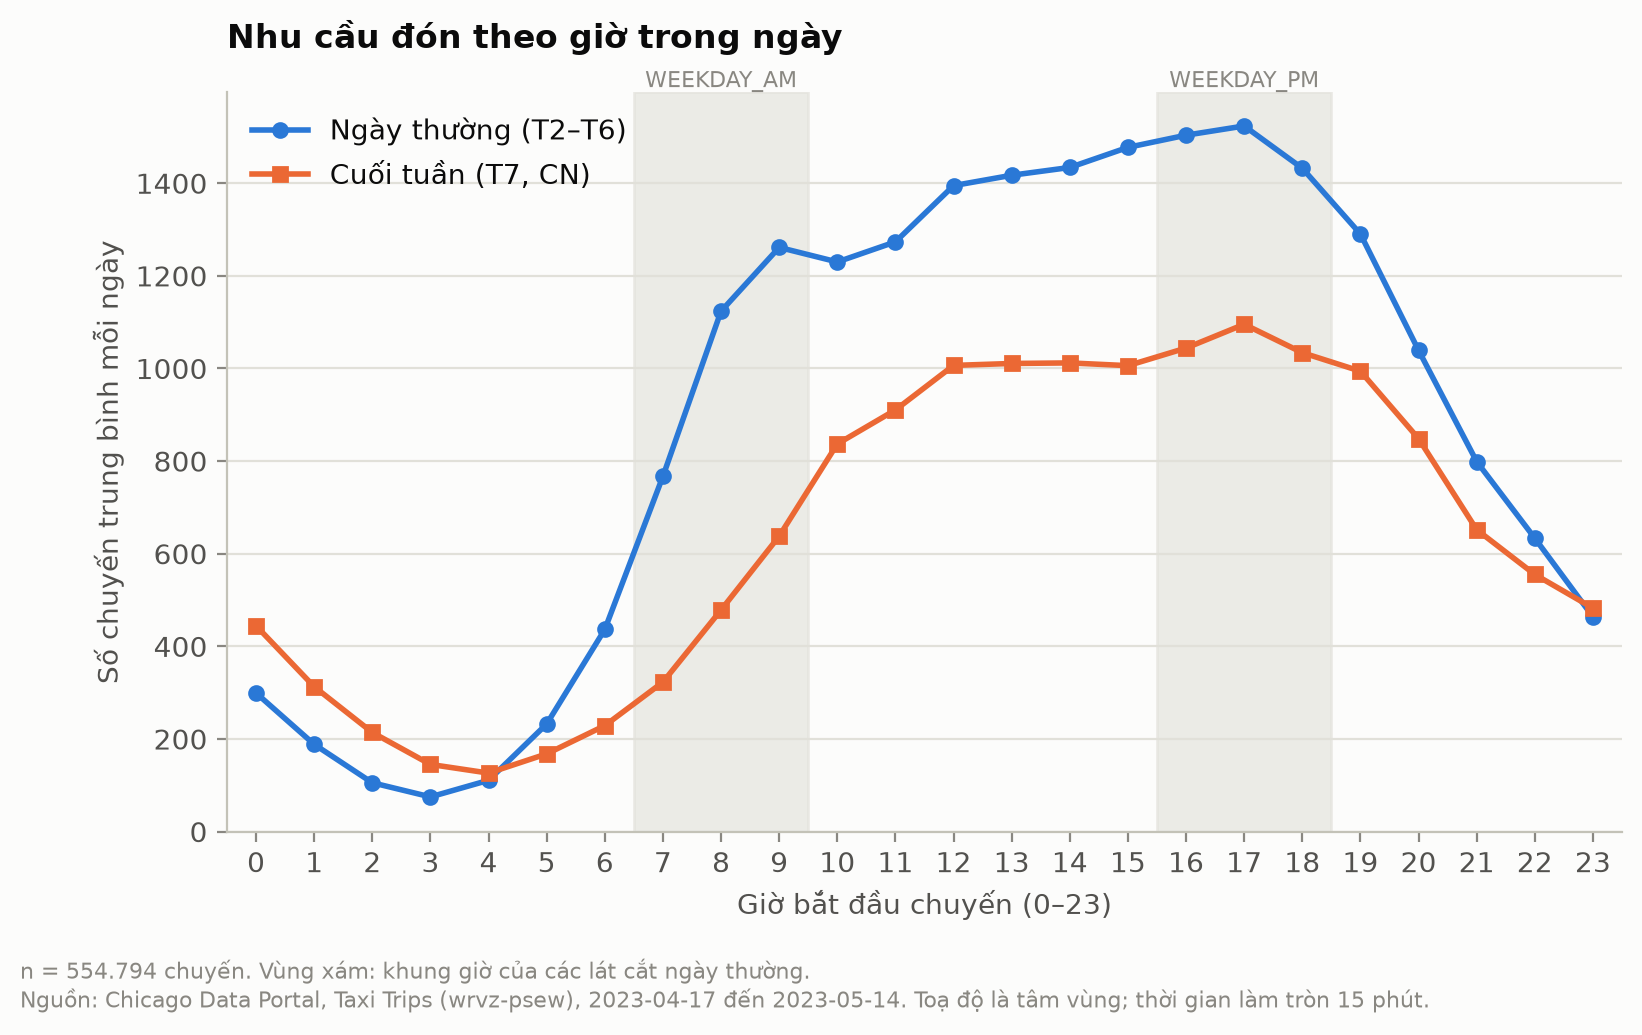
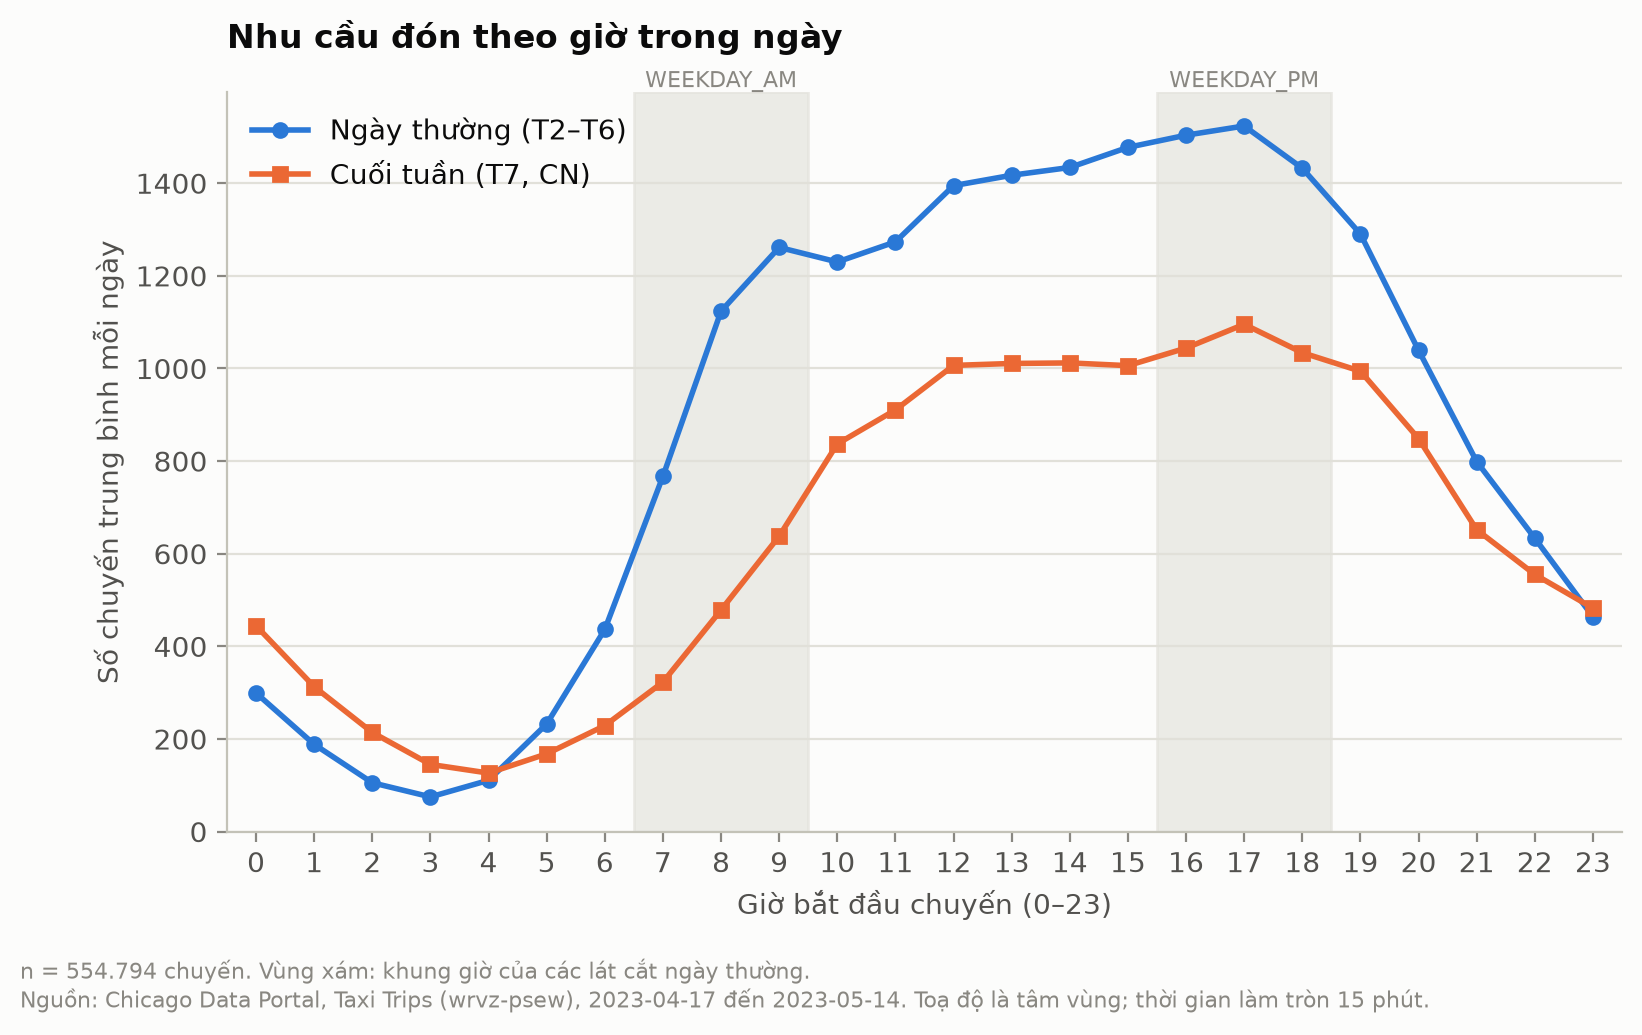
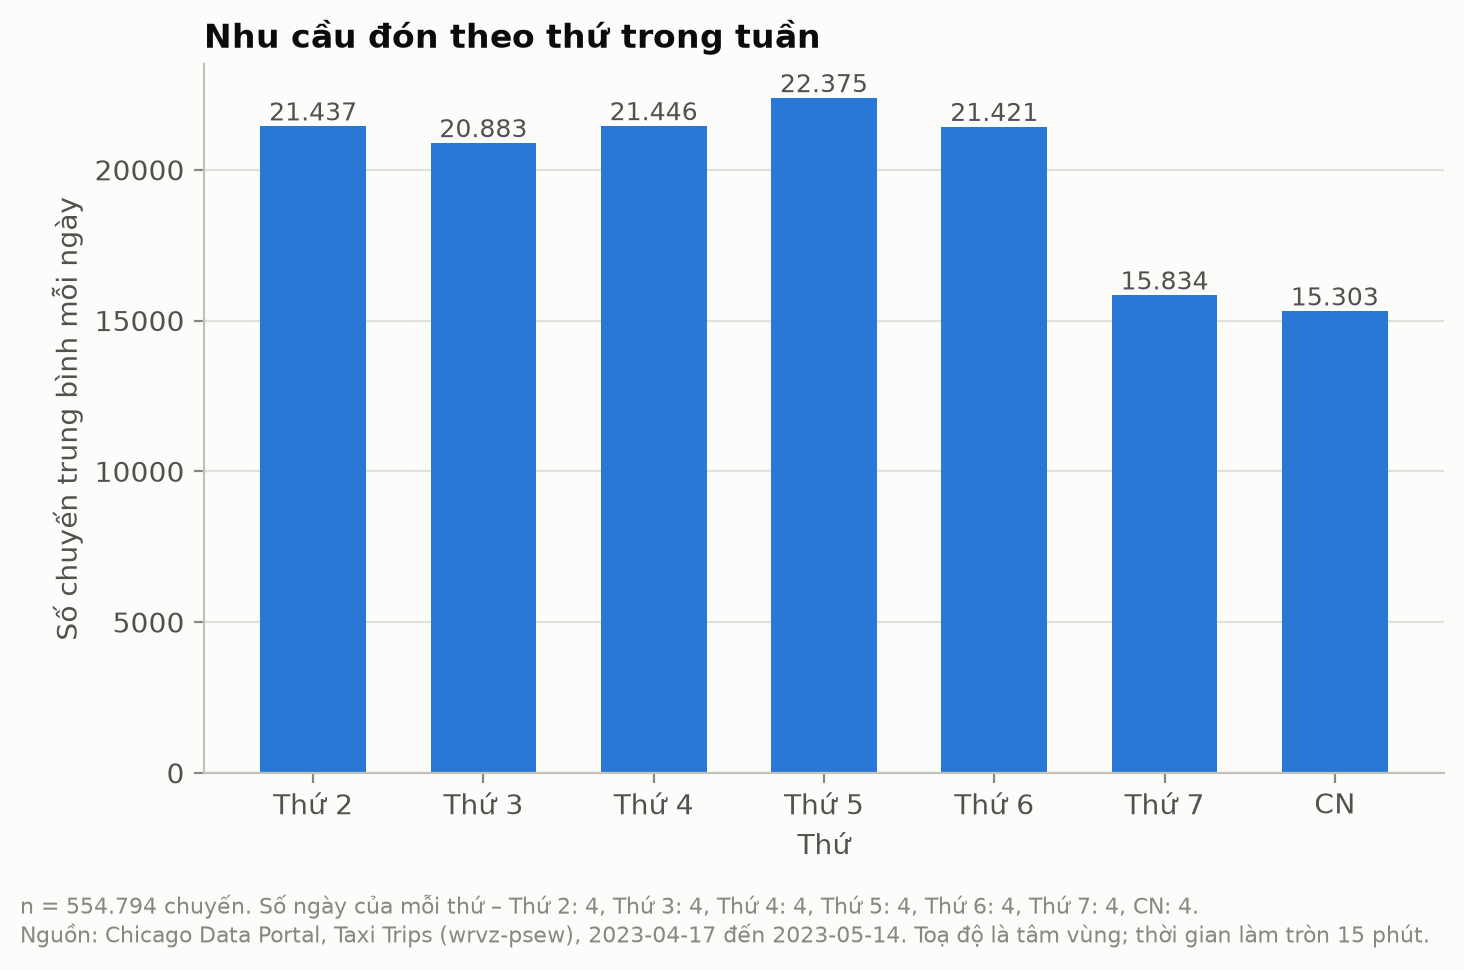
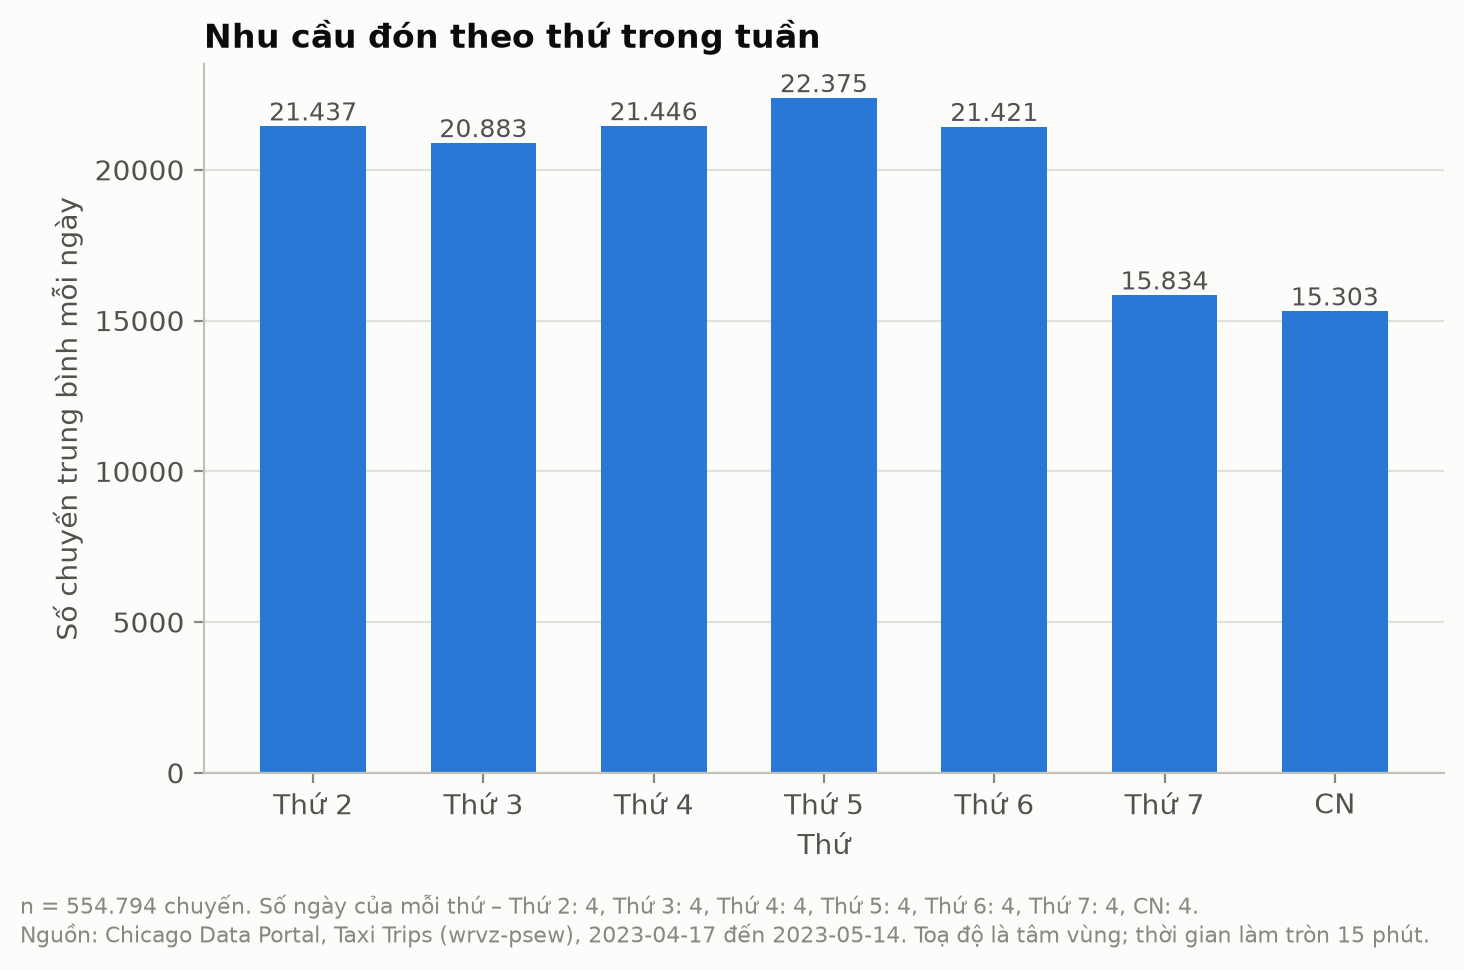
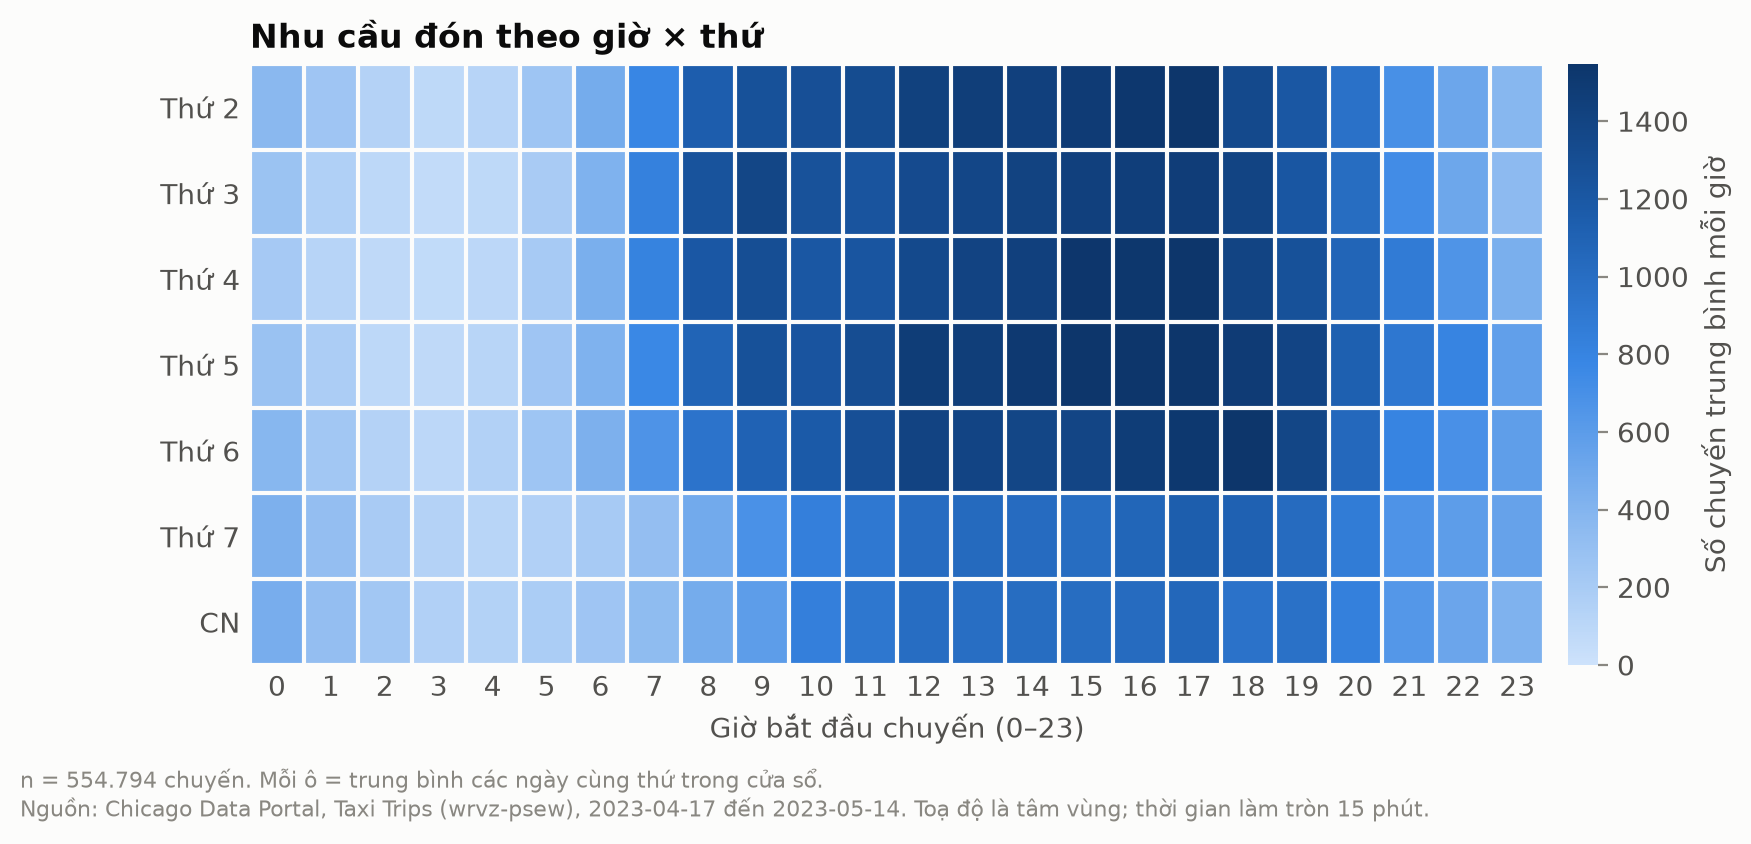
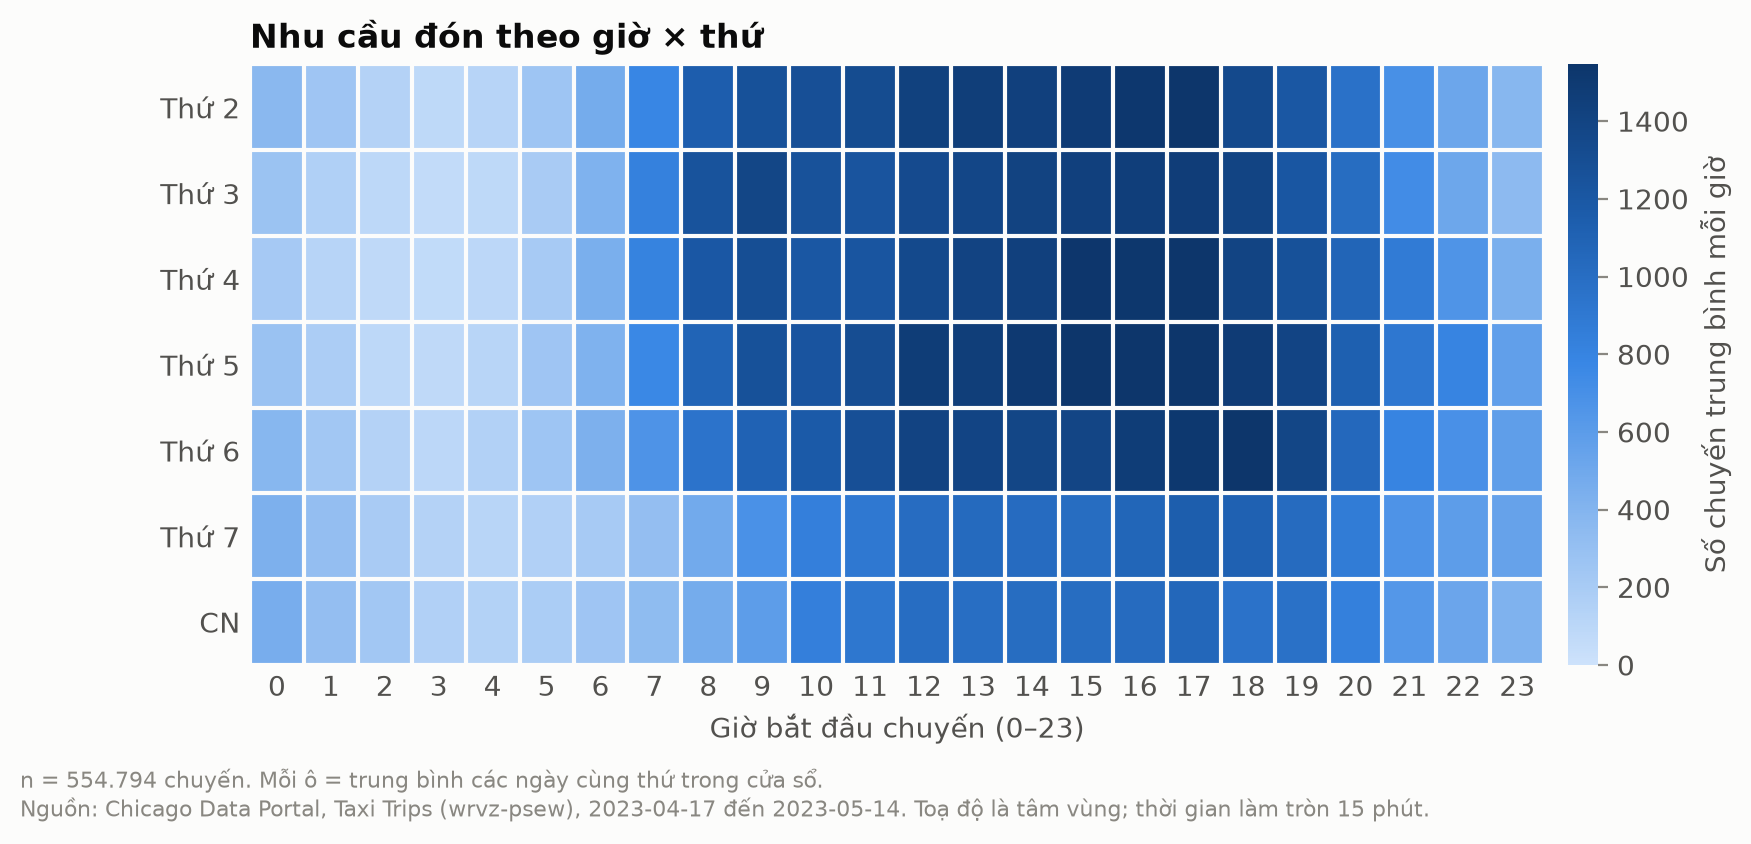
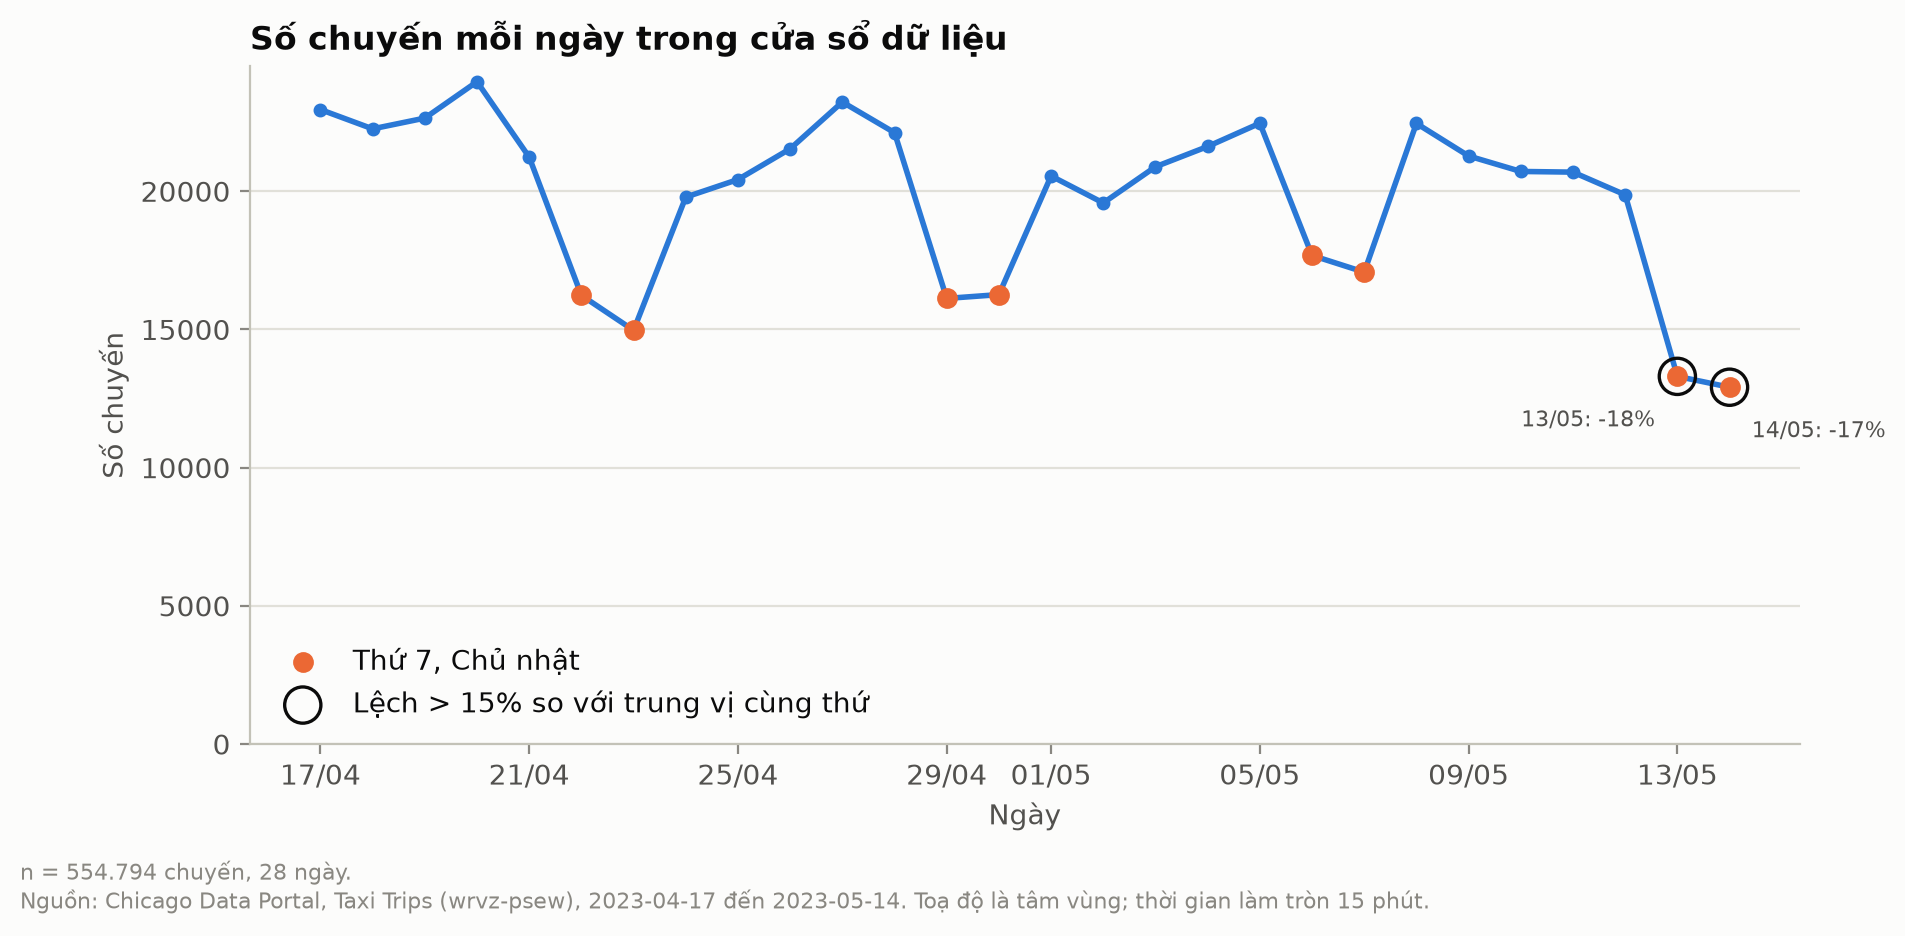
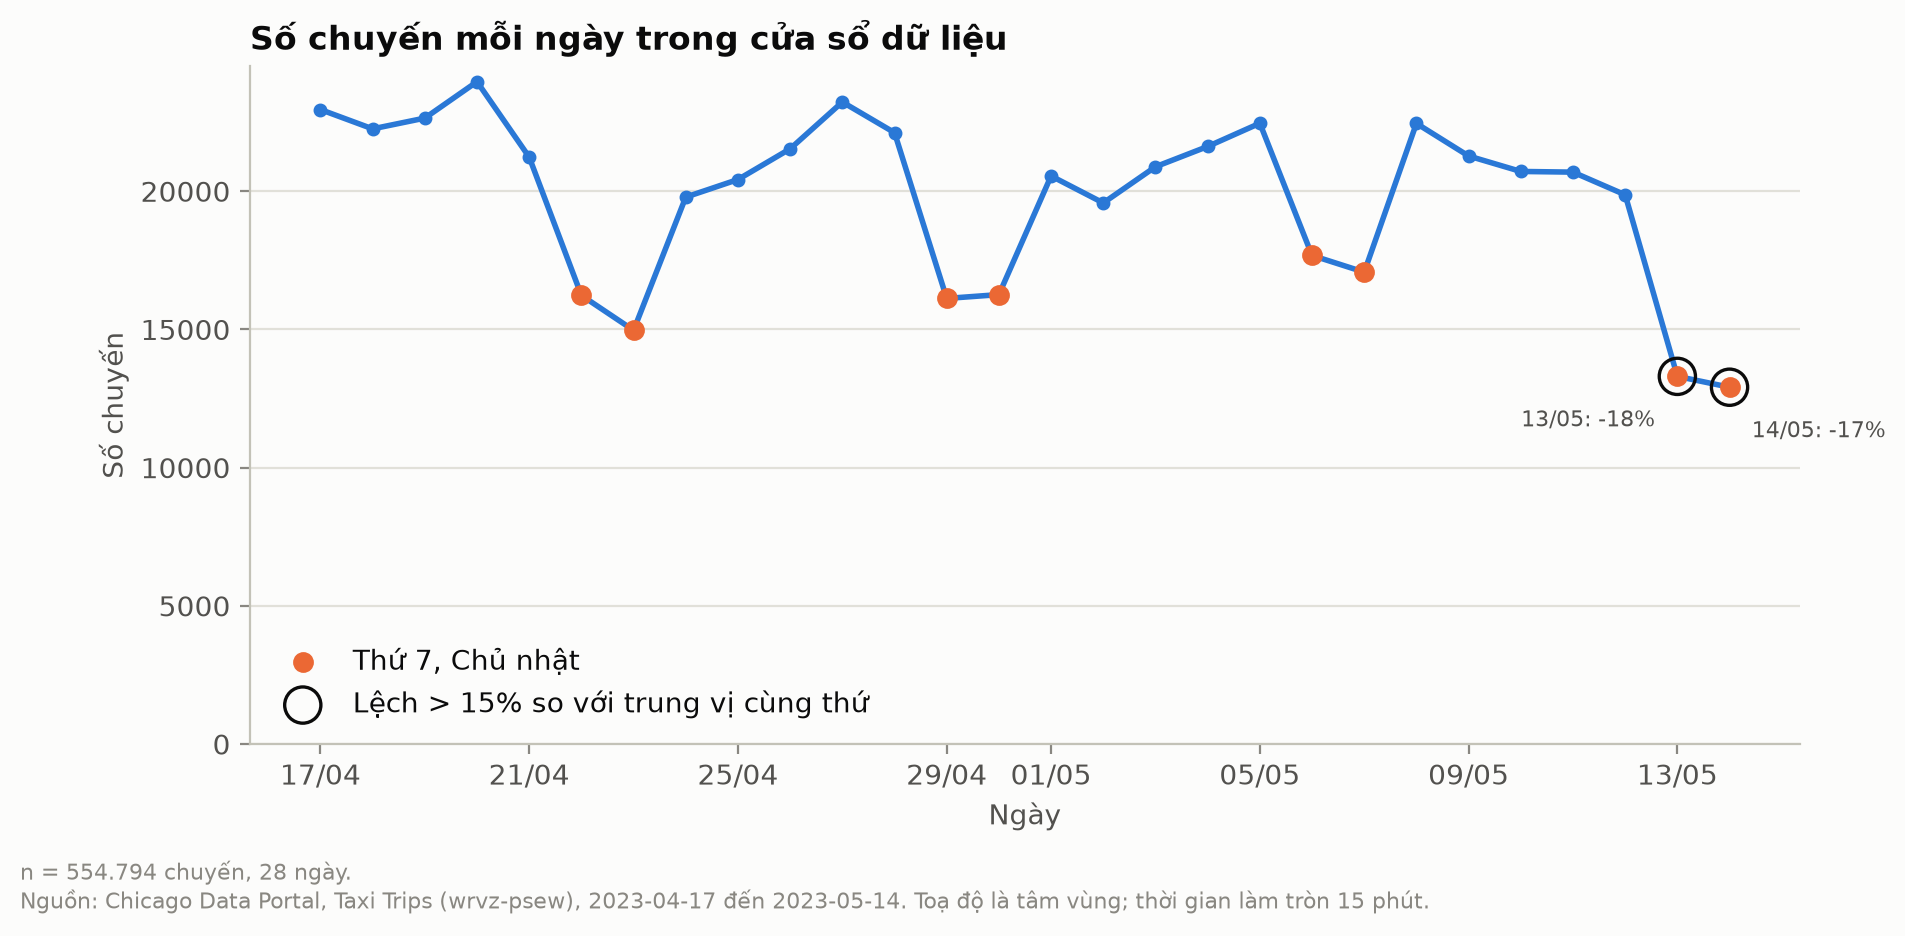
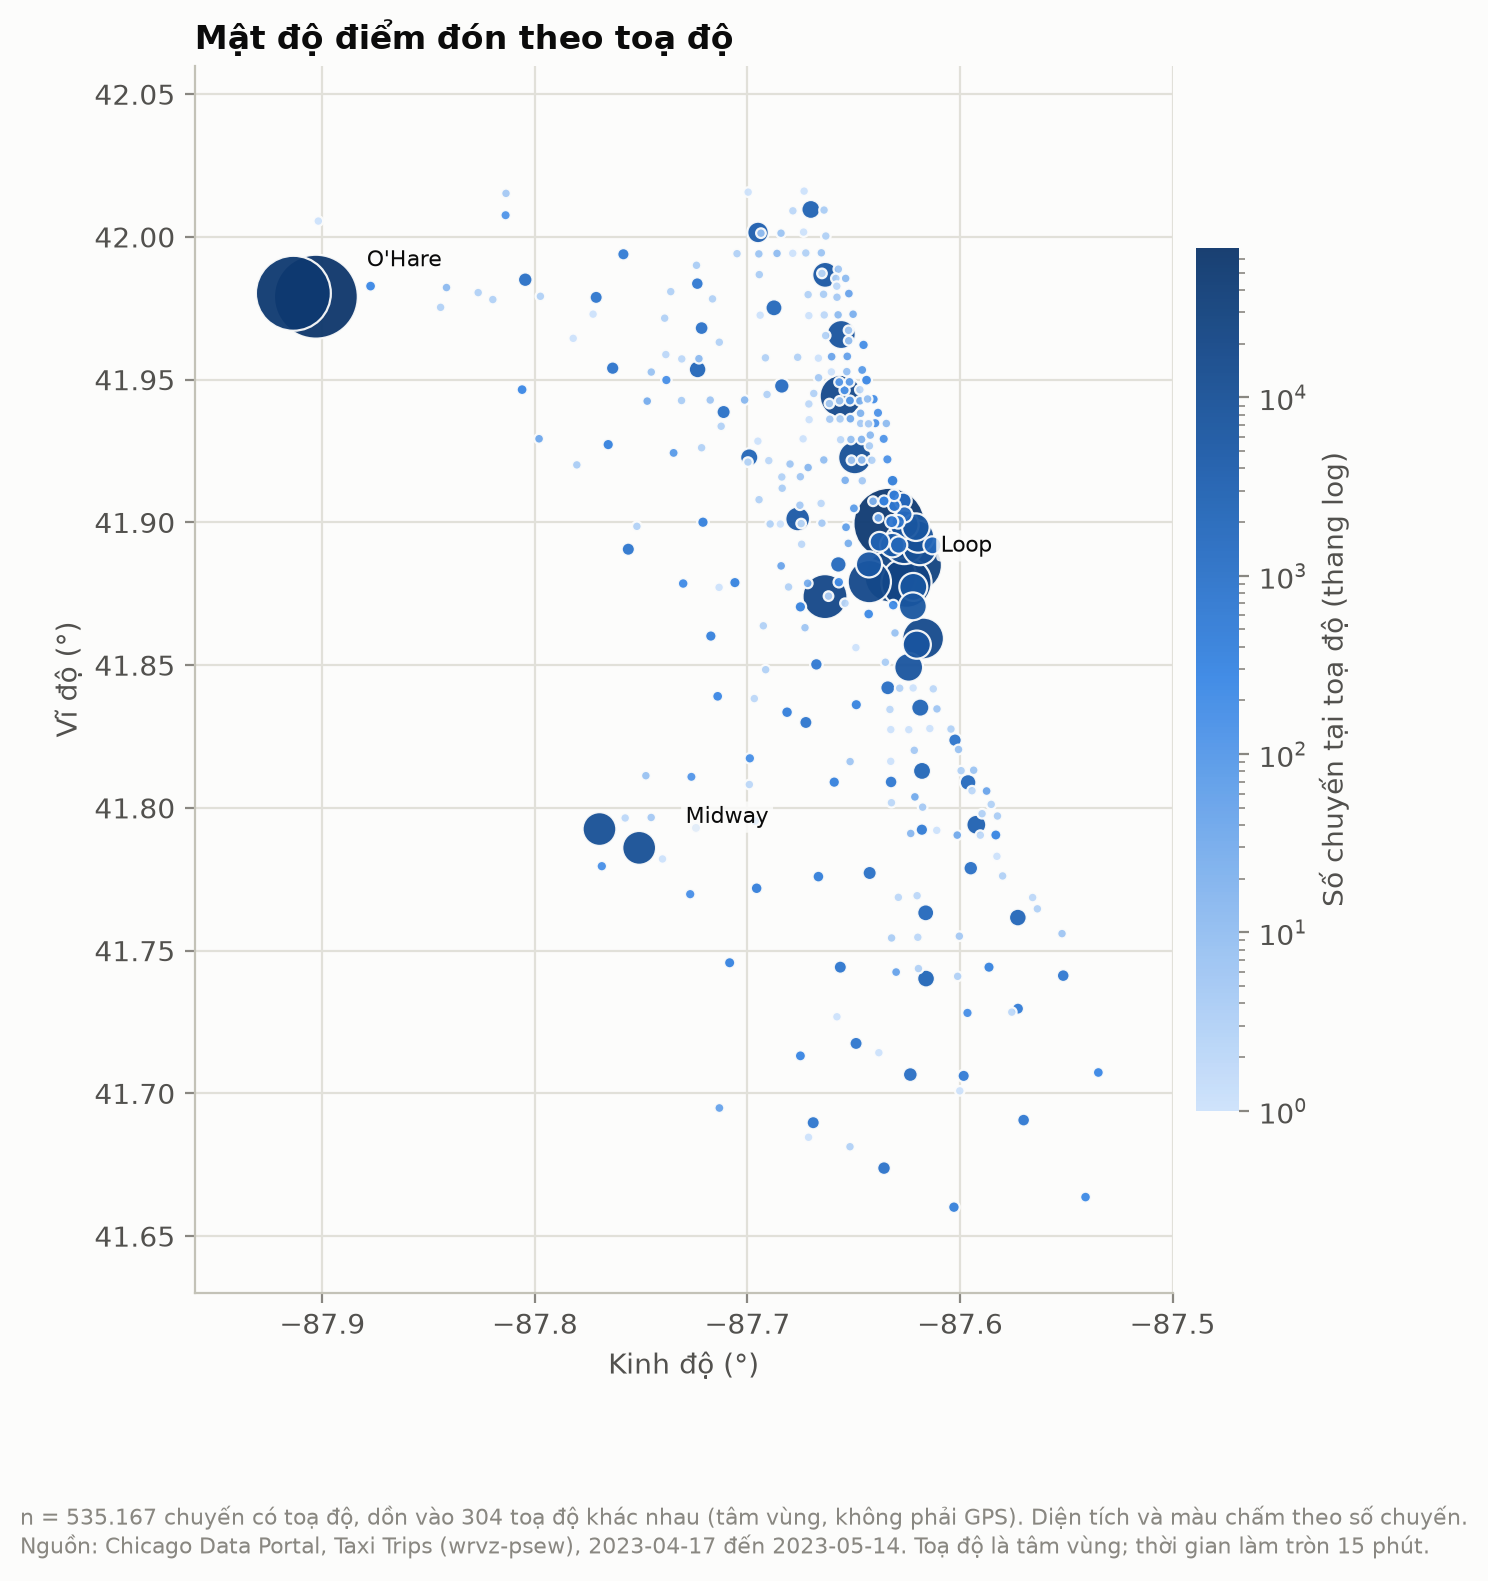
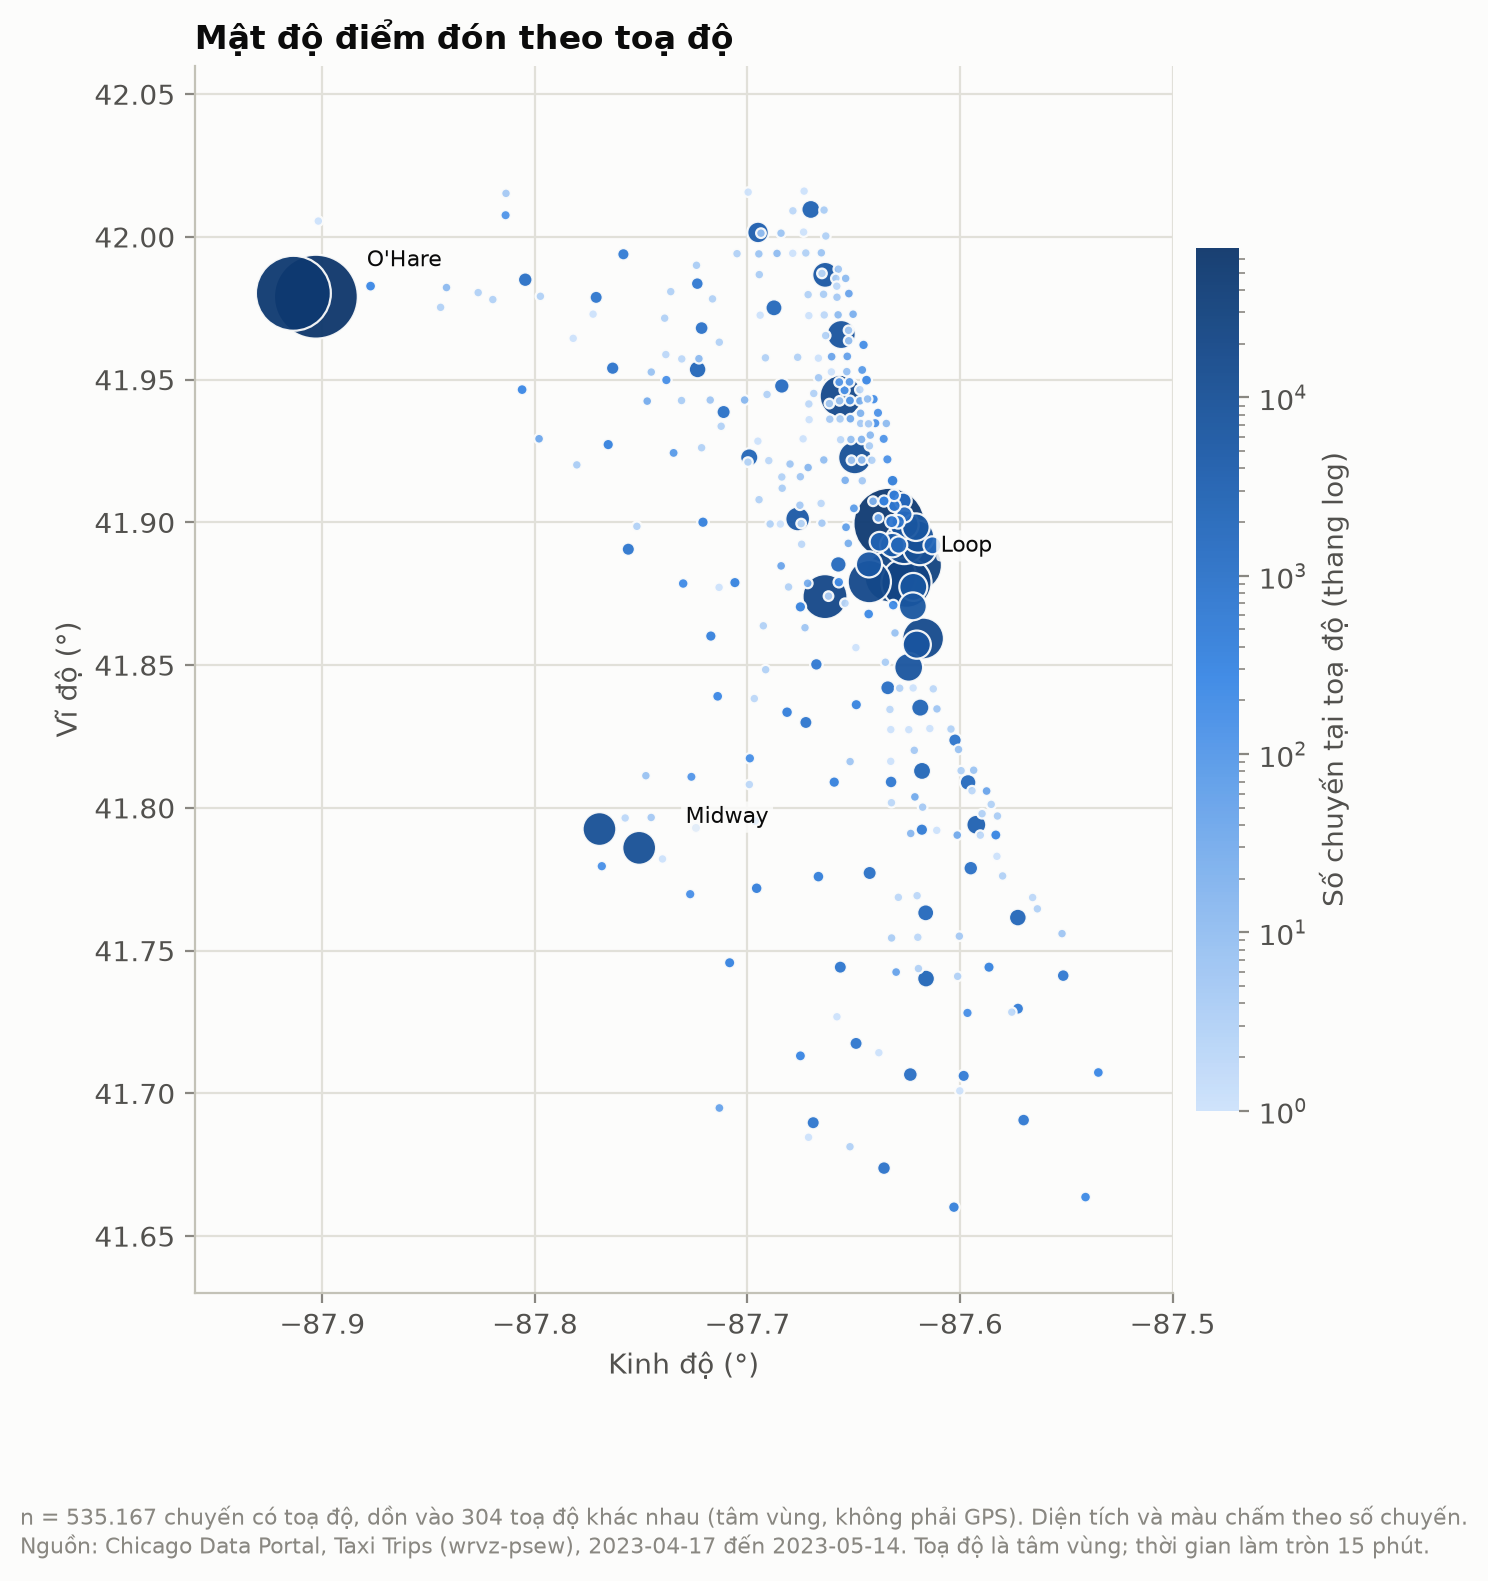
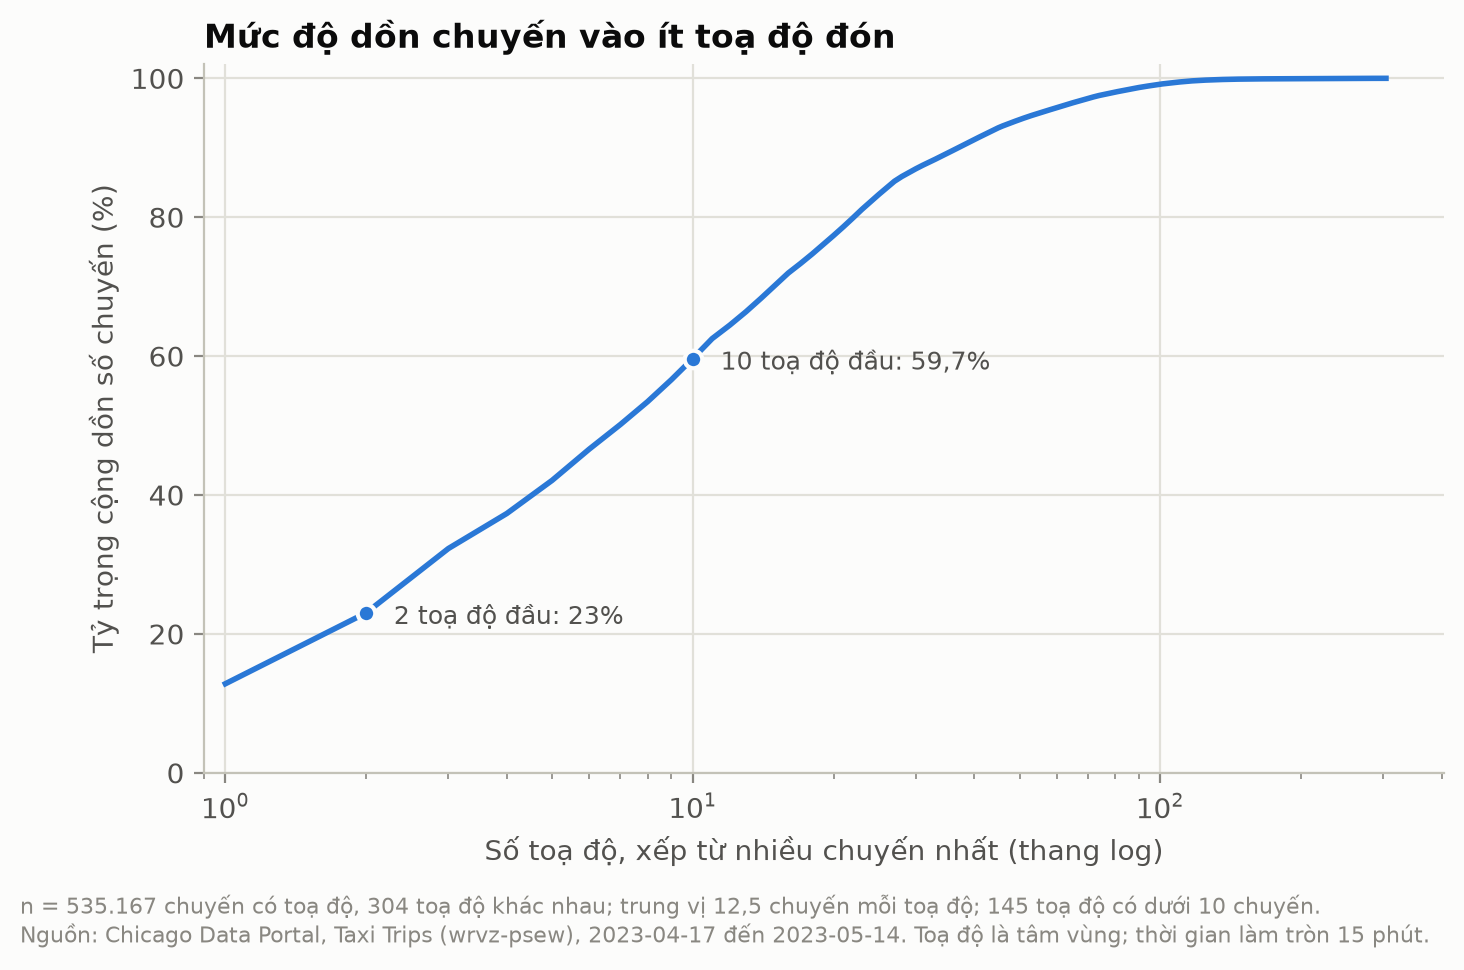
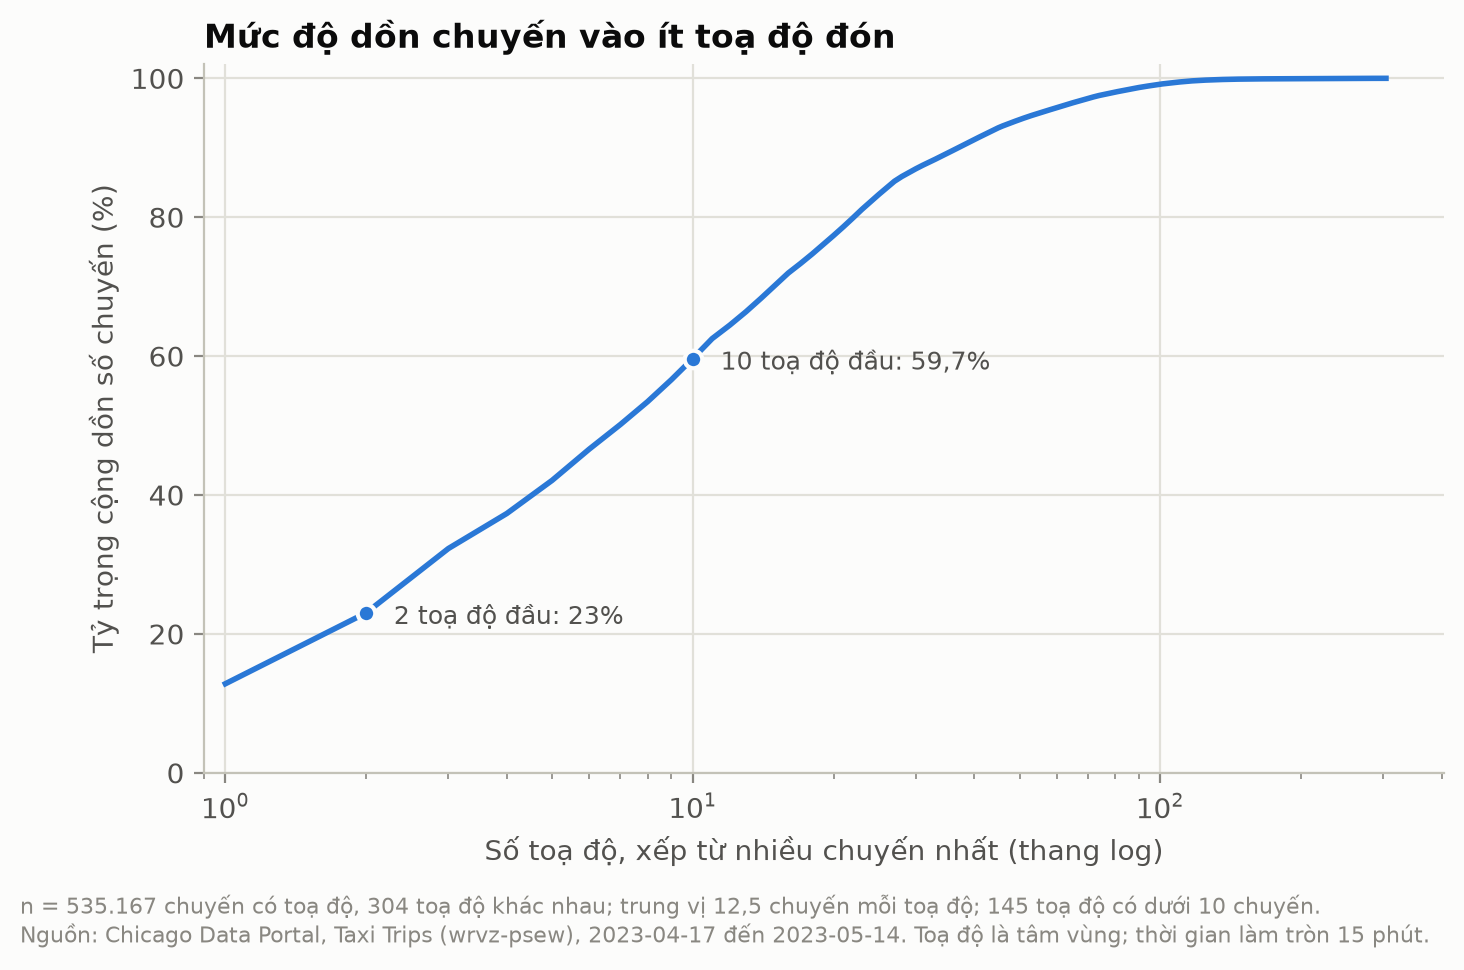
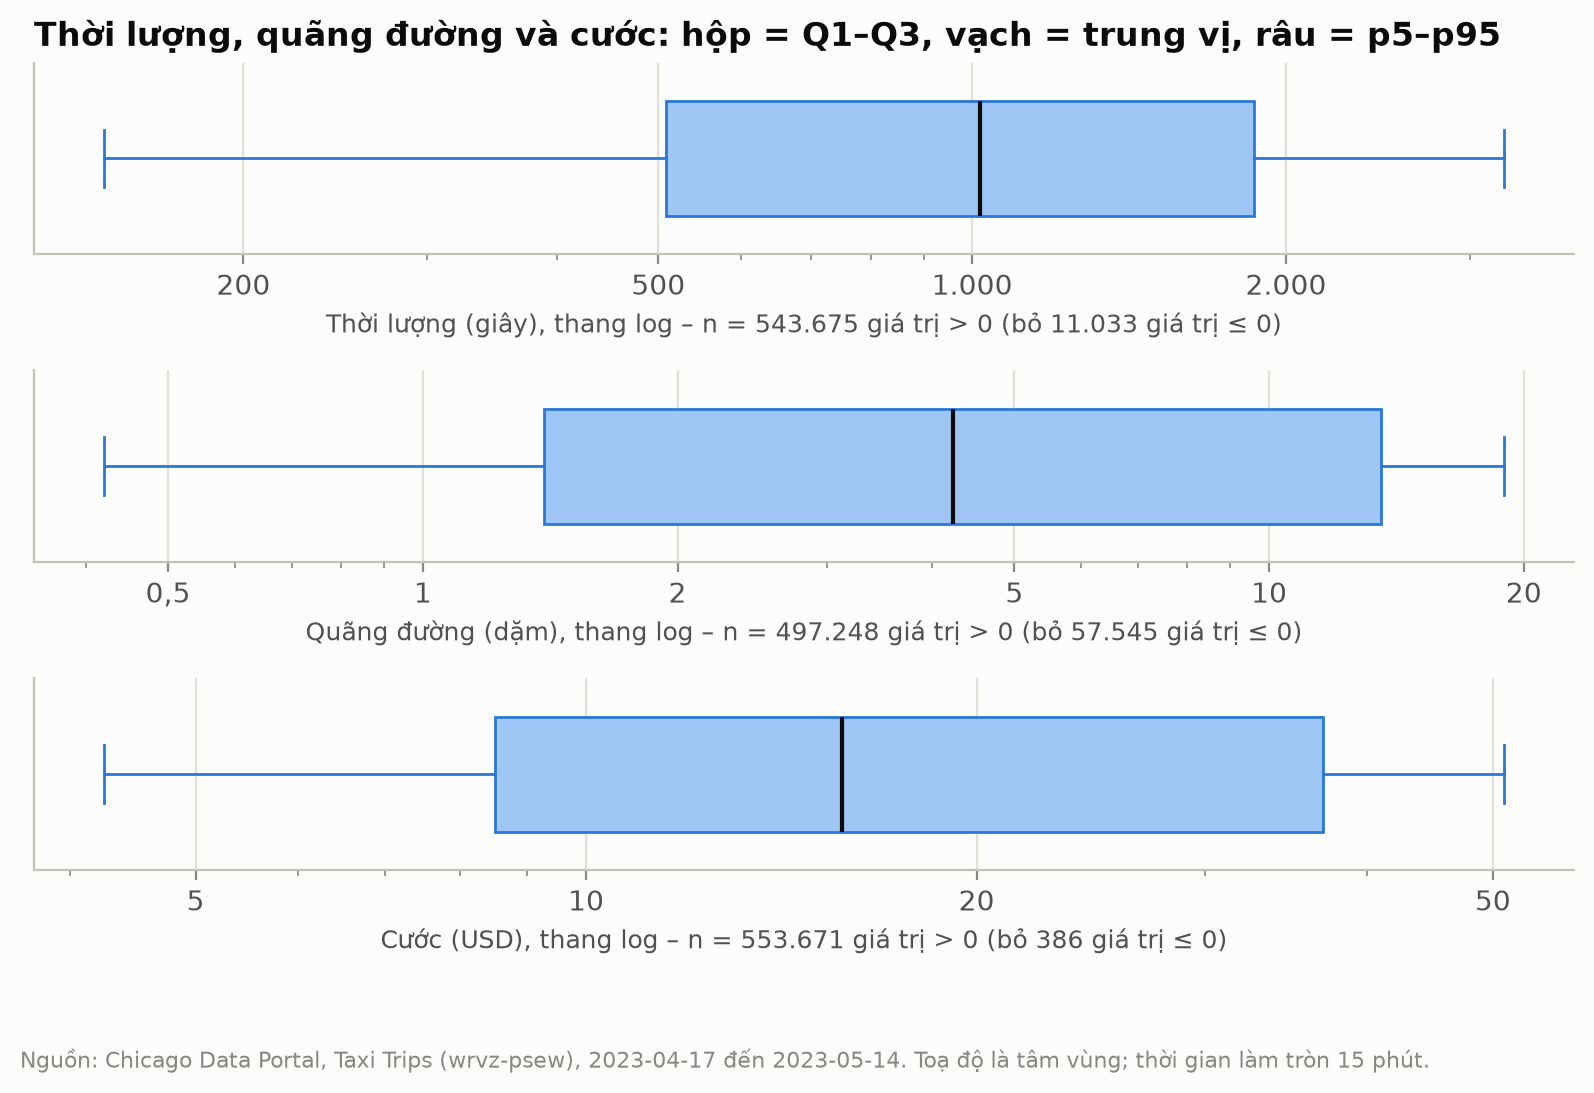
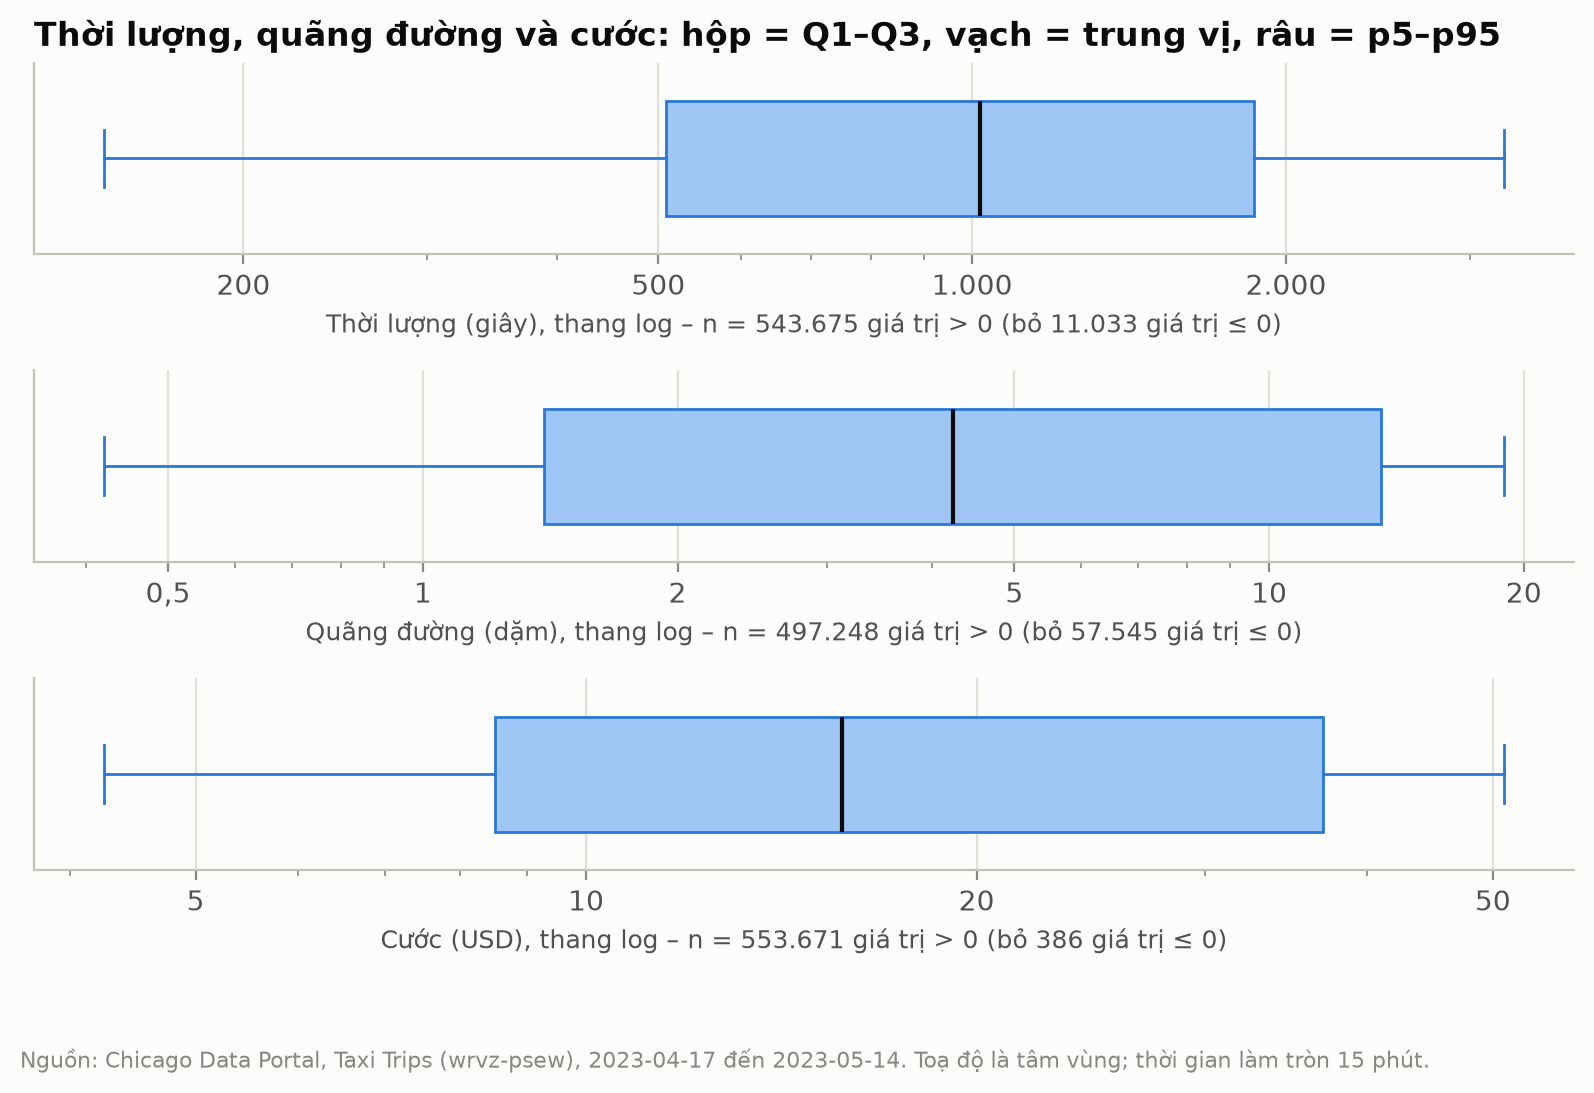
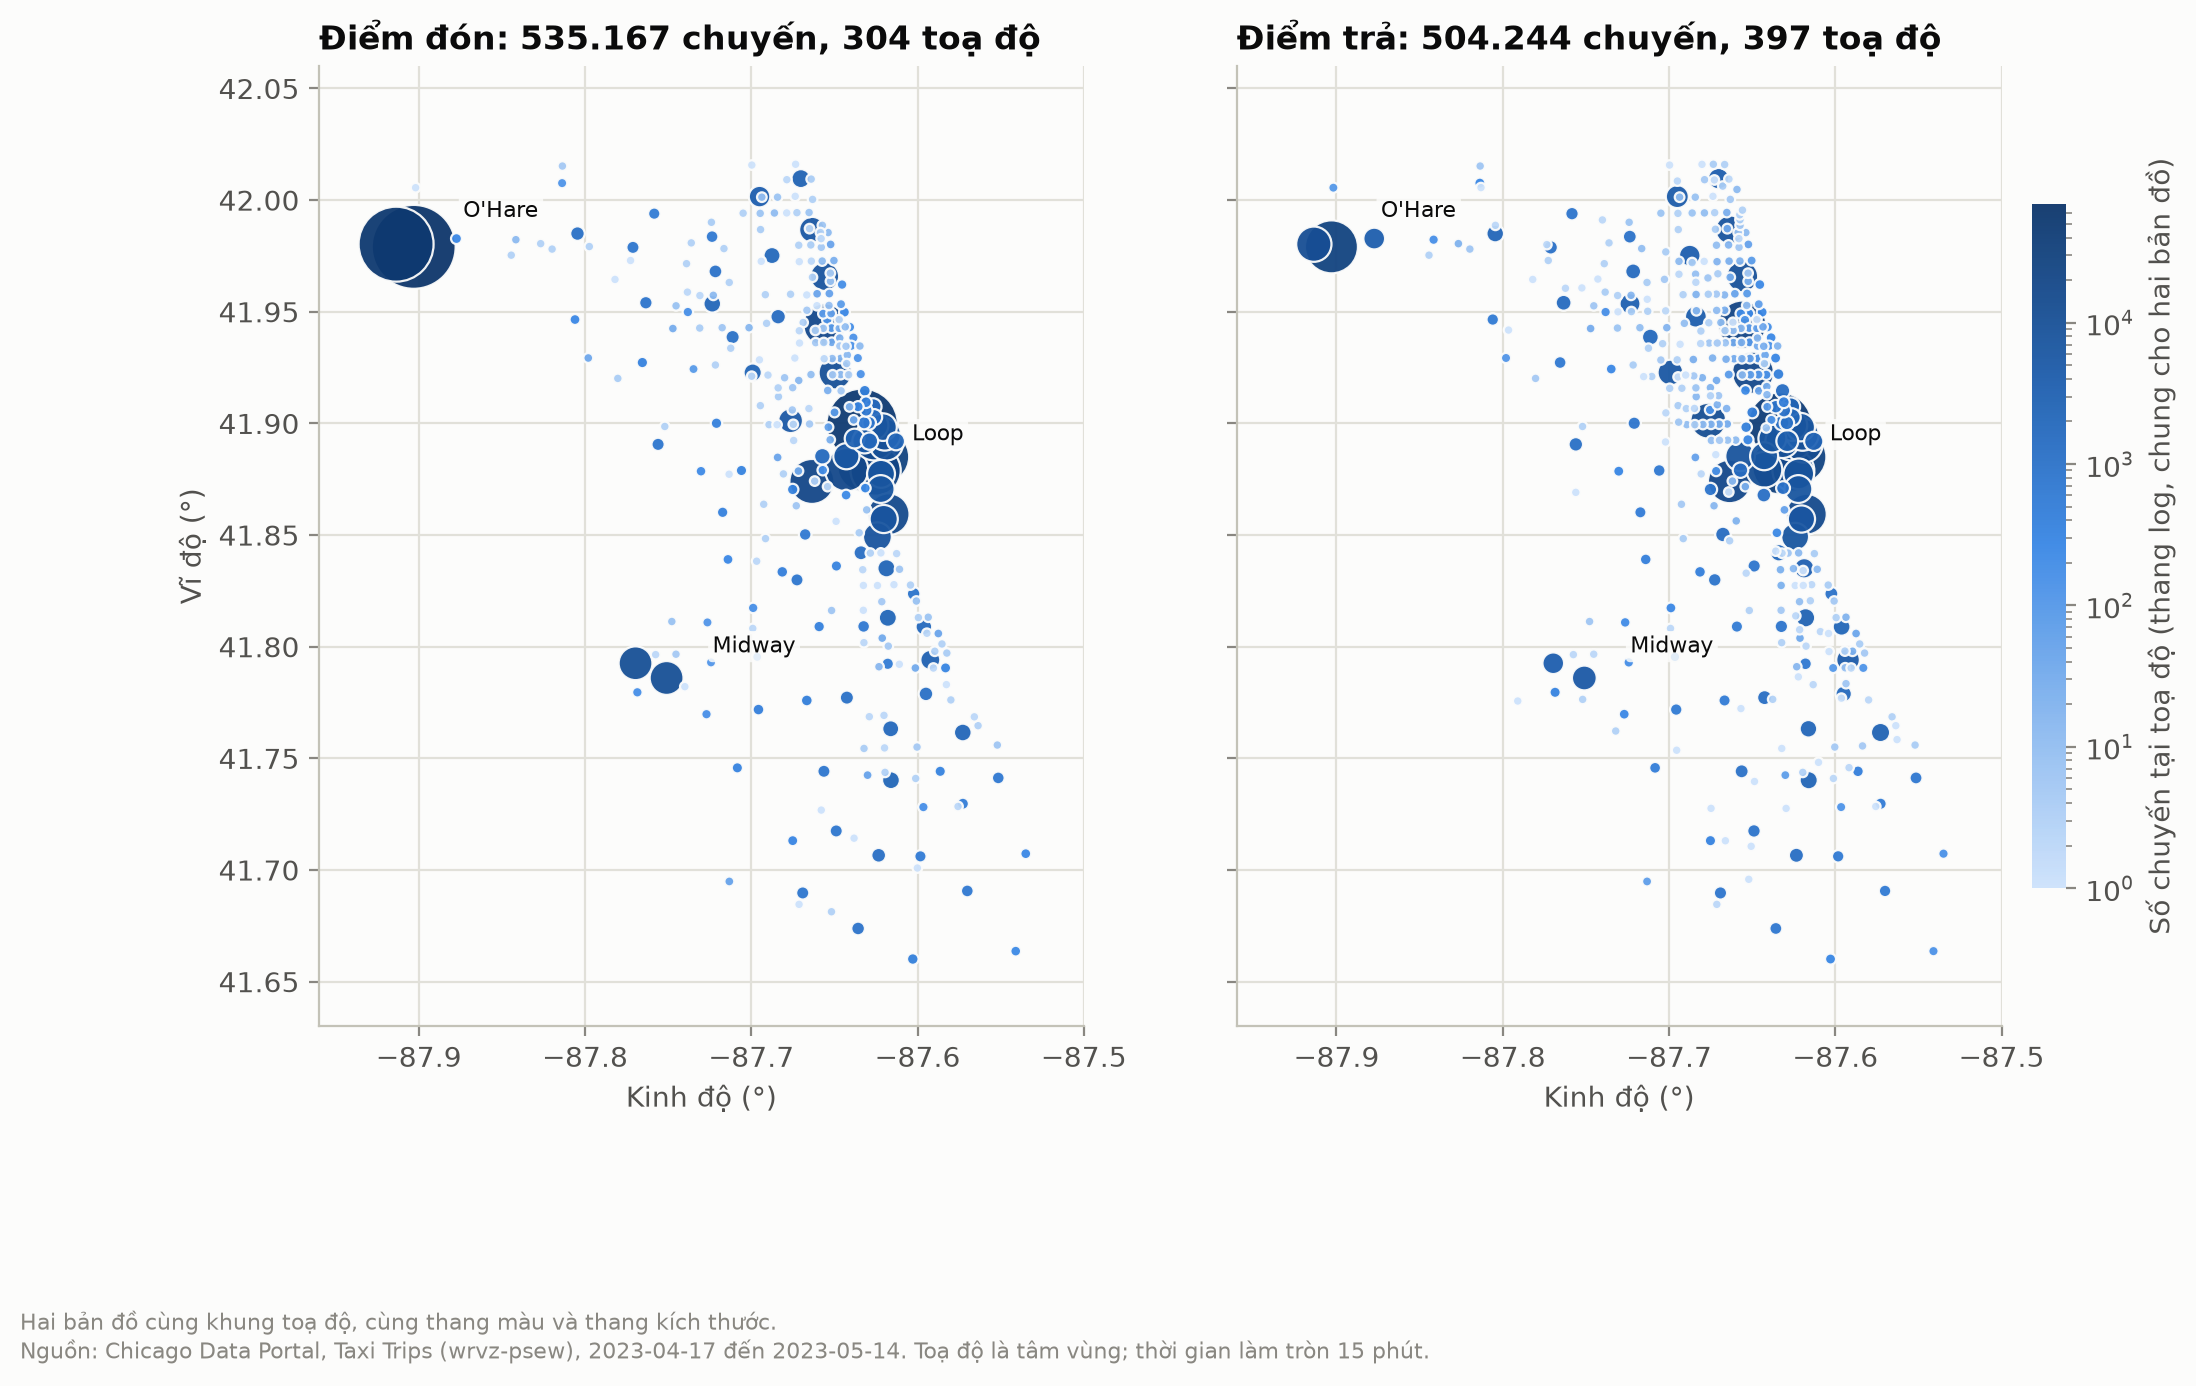
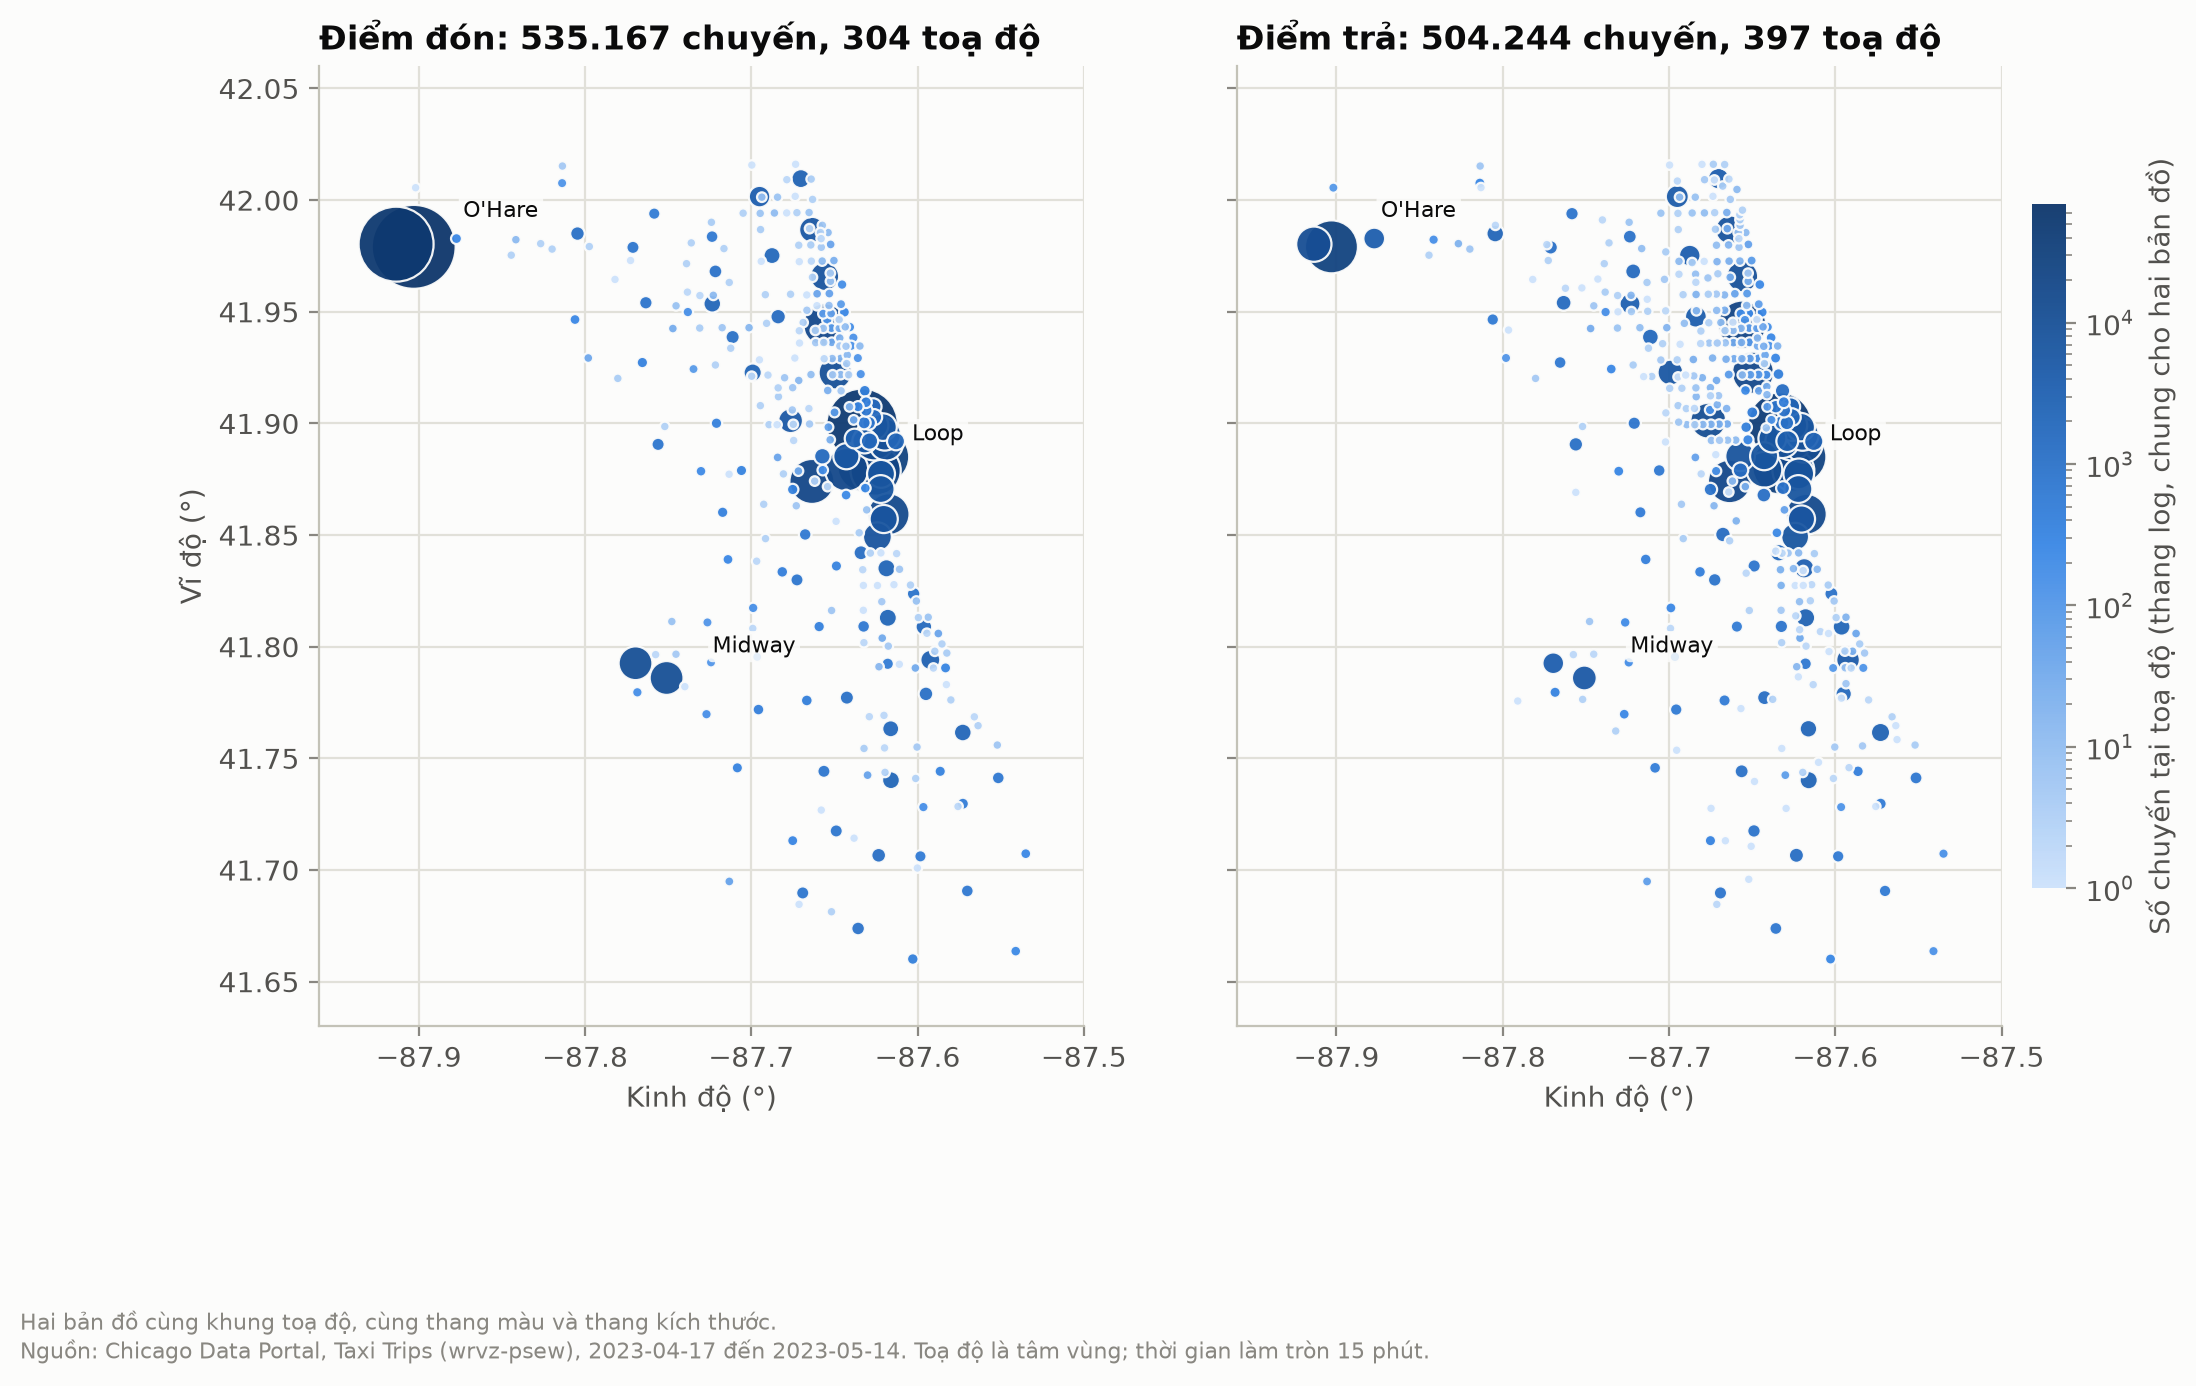

In [12]:
from IPython.display import HTML

if man:
    figs = A.write_figures(d, FIG_DIR, NOTE, cfg["time_slices"])     # 10 file PNG day du, dung cho bao cao
    display(HTML(A.figure_grid_html(figs)))                          # hien thi thu gon: luoi 2 cot theo chu de

## 7. Nhận xét từ EDA

<div style="font-size: 85%; line-height: 1.45">

Cửa sổ 17/04–14/05/2023, 554.794 chuyến. Số liệu lấy từ `outputs/metrics/eda_summary.csv` và các bảng trong `outputs/metrics/eda/`. Các nhận xét nói về **nhu cầu đón taxi**, không nói về ùn tắc.

**1. Chuyến đi dồn vào rất ít toạ độ.** 535.167 chuyến có toạ độ chỉ nằm trên 304 điểm (227 tâm census tract, 77 tâm community area); 7 điểm chiếm 50% số chuyến, trong khi 145 điểm có dưới 10 chuyến (Hình 06, 10).
→ Phân cụm thực chất là gom khoảng 300 điểm có trọng số rất chênh nhau. `min_samples` của DBSCAN nên đặt theo tỷ lệ số chuyến, và không diễn giải vị trí cụm chính xác hơn mức tract/khu.

**2. Có hai vùng nhu cầu tách rời: sân bay O'Hare và khu trung tâm.** Khu 76 (O'Hare) chiếm 22,2% số chuyến chỉ với hai toạ độ; ba khu trung tâm 8, 32, 28 chiếm 45,6%; bốn khu cộng lại 67,8% (Hình 06).
→ Kỳ vọng một cụm sân bay tách biệt và một vùng trung tâm đậm đặc. K-Means buộc mọi điểm vào cụm nên dễ bị hai khối này kéo lệch tâm.

**3. Nhu cầu có chu kỳ rõ, đỉnh ở buổi chiều.** Cuối tuần thấp hơn ngày thường 28% (15.600 so với 21.500 chuyến mỗi ngày). Ngày thường đạt đỉnh lúc 15–17 giờ; khung chiều 16–18 giờ cao hơn khung sáng 7–9 giờ 41% (Hình 03, 04, 05).
→ Tách lát cắt thời gian là hợp lý. WEEKDAY_AM nhỏ nhất (60.498 chuyến có toạ độ, 11,3%), cần kiểm tra cỡ mẫu khi lấy mẫu chung.

**4. Điểm đón và điểm trả không đối xứng.** O'Hare chiếm 23,0% lượt đón nhưng chỉ 7,7% lượt trả; điểm trả phân tán hơn (397 toạ độ so với 304). Quãng đường có hai đỉnh: 13,2% số chuyến dài 16–19 dặm, và 96% trong đó có một đầu ở O'Hare (Hình 02, 07).
→ Cụm tìm được mô tả nơi phát sinh nhu cầu, không phải nơi đến. Thuộc tính chuyến đi khác hẳn giữa hai nhóm, nên baseline chỉ dùng `[x_m, y_m]`.

**5. Dữ liệu sạch về định danh, thời gian, toạ độ.** Không trùng `trip_id`, không thiếu ngày, không có điểm ngoài khung Chicago. Chỉ loại 3,54% dòng do thiếu toạ độ đón, còn lại 535.167 dòng. Riêng 10,4% số chuyến có quãng đường bằng 0, dao động 2,2–25,7% tuỳ hãng, nhiều khả năng do thiết bị ghi thiếu (bảng `quality_checks.csv`).
→ Các dòng này được gắn cờ chứ không loại, vì quãng đường không nằm trong ma trận đặc trưng.

**6. Cuối tuần 13–14/05 thấp bất thường, chưa rõ nguyên nhân.** Thấp hơn 20% so với trung bình ba cuối tuần trước, và giảm không đều: khu 33 giảm 73%, Loop 34%, O'Hare 17% (Hình 09).
→ Giả thuyết là Ngày của Mẹ (14/05) hoặc các tuần trước có sự kiện lớn ở khu 33; **chưa kiểm chứng**. M3 cần lưu ý vì lát cắt WEEKEND chứa hai ngày này.

**Giới hạn:** toạ độ là tâm vùng và thời gian làm tròn 15 phút, nên không kết luận ở mức tuyến phố hay phút; bốn tuần mùa xuân 2023 không đại diện cả năm; dữ liệu chỉ gồm taxi truyền thống.

</div>

## 8. Chép kết quả về Drive (chỉ khi chạy trên Colab)

Thư mục `outputs/` trên Colab mất khi đóng phiên, nên chép bảng và hình sang `KhaiPhaDuLieu/data/eda_outputs` trên Drive. Tải thư mục đó về máy, đặt vào `outputs/` của repo rồi mới commit. Chạy trên máy cá nhân thì kết quả đã nằm sẵn trong repo, ô này không làm gì.

In [13]:
import shutil

if man and IN_COLAB:
    dst = RAW_DIR.parent / "eda_outputs"
    shutil.copytree(FIG_DIR, dst / "figures" / "eda", dirs_exist_ok=True)
    shutil.copytree(METRICS_DIR / "eda", dst / "metrics" / "eda", dirs_exist_ok=True)
    shutil.copy2(METRICS_DIR / "eda_summary.csv", dst / "metrics" / "eda_summary.csv")
    print("Da chep ve Drive:", dst)

## 9. Tiếp theo

Làm sạch (có cleaning log), chiếu EPSG:26916, tạo đặc trưng thời gian, lấy mẫu phân tầng và phát hành `model_input` nằm ở notebook 02.